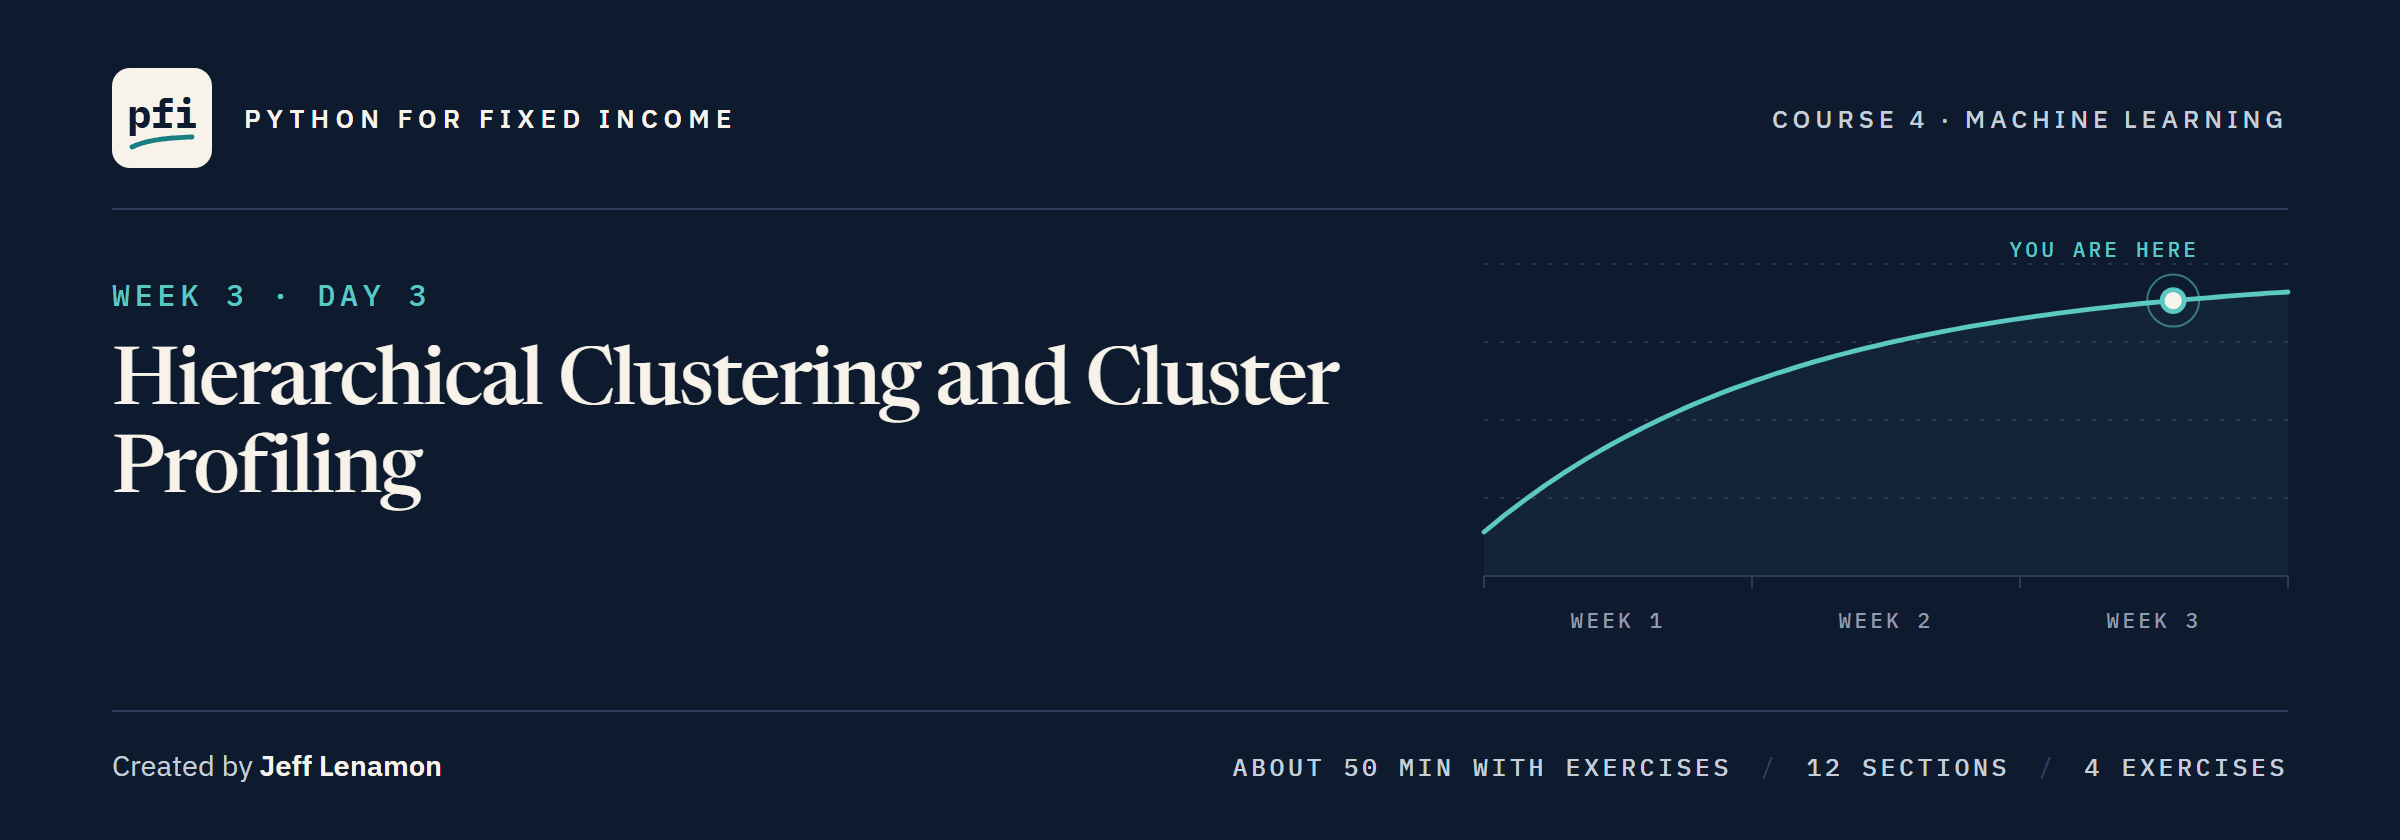

# Hierarchical Clustering and Cluster Profiling

Week 3, Day 3. Group the 150 issuers from the bottom up into a tree, choose where to cut it, and describe each cluster in bp, years and billions.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day3/13_hierarchical_clustering_and_cluster_profiling.ipynb)

# Problem Statement

## Business Context

The 821 bonds of the benchmark come from 150 issuers.
A credit team wants the issuers grouped by spread, duration, size and rating.
Before choosing how many groups, it wants to see the whole family tree of who resembles whom.
Then it wants one readable line per group, in the desk's own units.
The bonds and issuers are invented for this course.

## Objectives

Build one row per issuer, join the issuers from the bottom up into a tree, read the tree and cut it, compare four ways of joining, and describe each cluster in bp, years and billions beside Day 12's K-means.

## Data Dictionary

Today's table has one row per issuer, built from `benchmark.csv`'s bonds:

1. `ticker`, `issuer`, `sector`: who the issuer is (`issuers.csv`)
2. `rating`, `score`, `grade`: the issuer's rating, its score (1 for AAA up to 18 for CCC) and grade (`ratings.csv`)
3. `median_oas`: the median OAS of its bonds, bp
4. `median_log_oas`: the median of its bonds' log OAS
5. `median_duration`: the median duration of its bonds, years
6. `bonds`: how many bonds it has in the file
7. `amount_bn`: the face value of its bonds added up, billions of dollars

The clusters are built on `median_log_oas`, `median_duration`, `bonds`, `amount_bn` and `score`.
The sector is shown, never clustered.

## Your Route Through Day 3

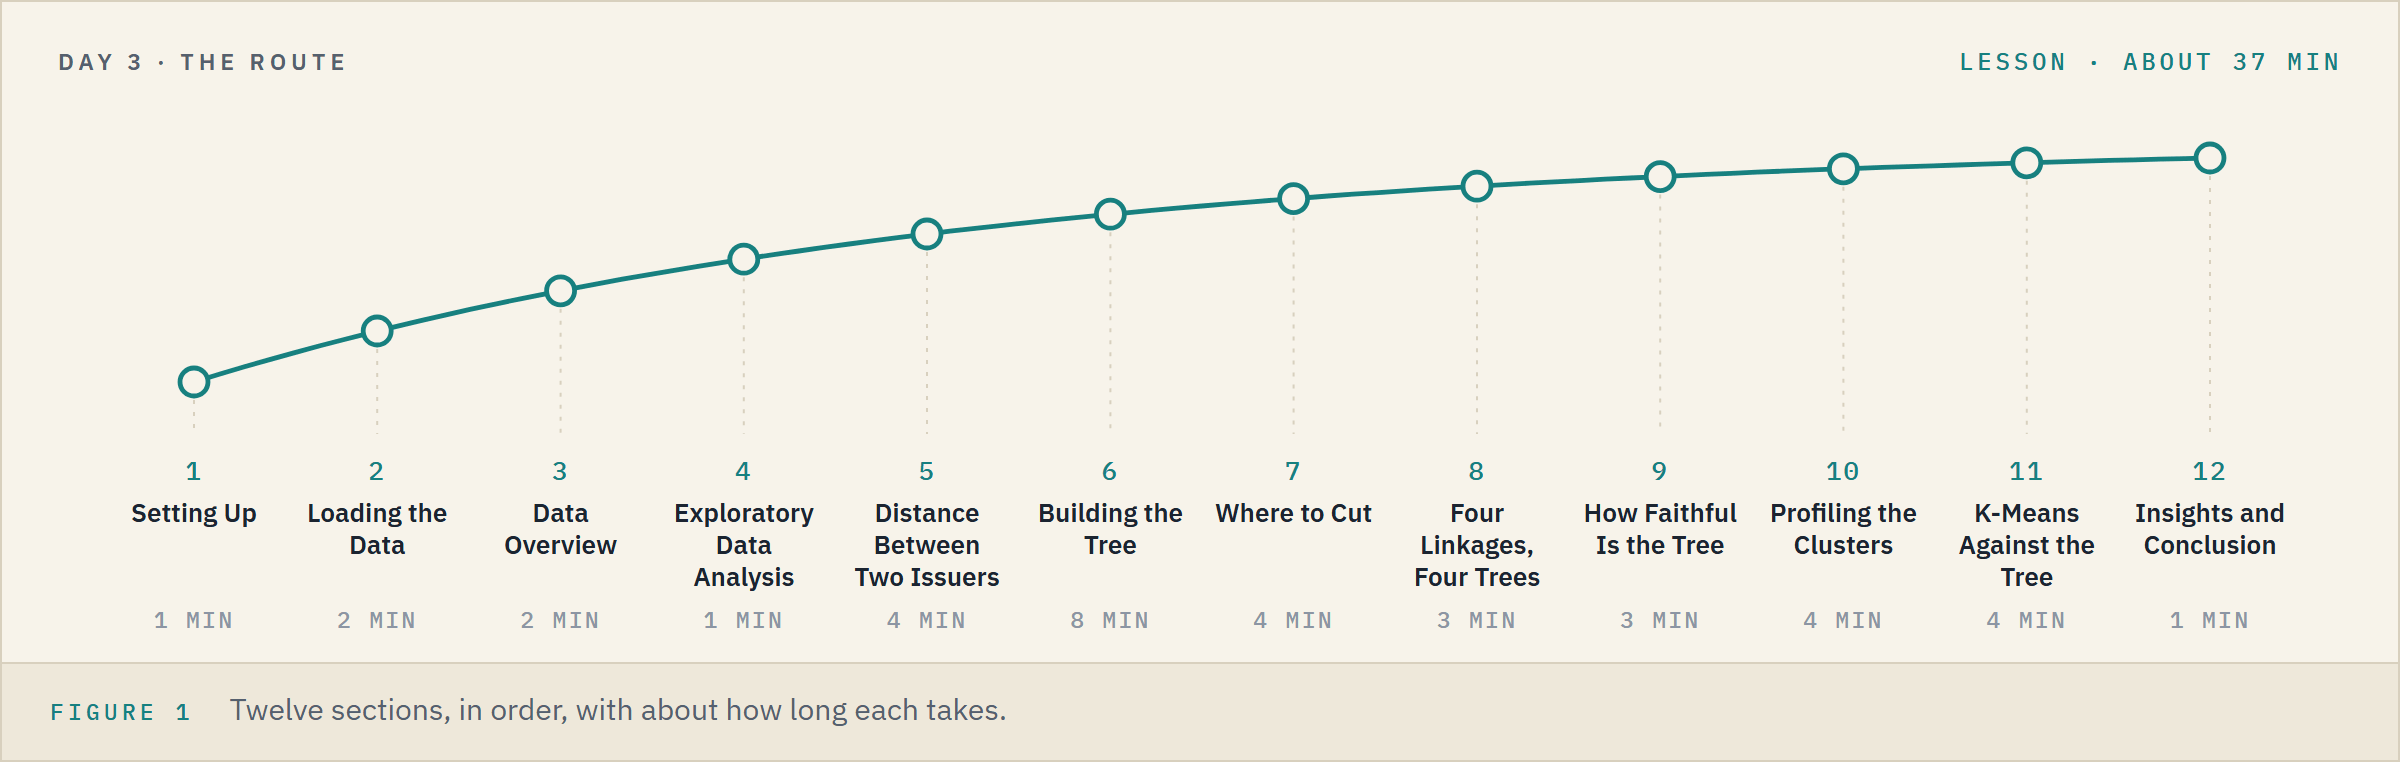

**Time.** About 37 minutes for the lesson, then about 12 for the four exercises.

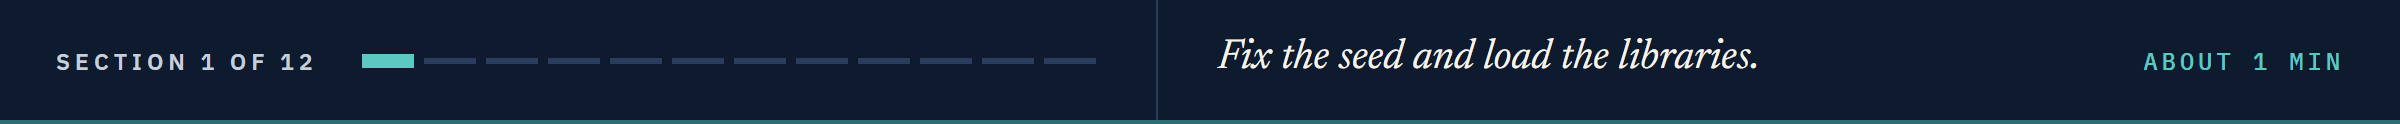

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to measure distances, build and cut the tree, and set it beside K-means
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet, set_link_color_palette
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# one colour per cluster, Day 12's: the colour-blind set with its pink moved ahead of its red
colours = sns.color_palette("colorblind").as_hex()
colours = [colours[i] for i in [0, 1, 2, 4, 3]]
# the set's other five colours after them, for cuts of up to ten clusters
colours = colours + sns.color_palette("colorblind").as_hex()[5:]

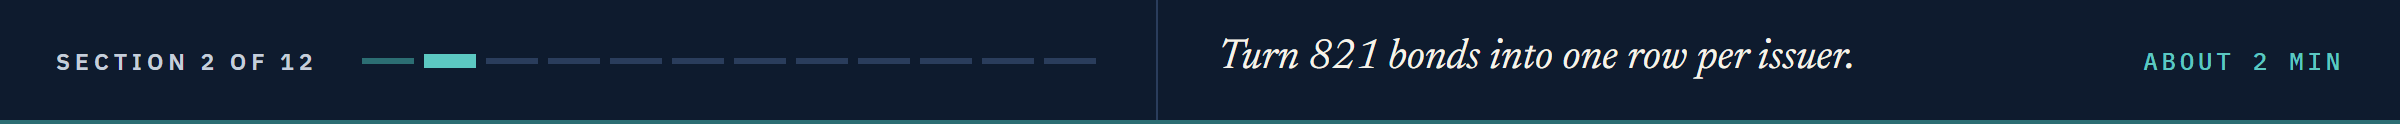

# Loading the Data

## Reading the Bonds, the Rating Scale and the Issuers

In [3]:
# the 821 bonds, the rating scale, and the list of 150 issuers
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
names = pd.read_csv(DATA + "issuers.csv")

# OAS on a log scale, as Day 4 used it
bonds["log_oas"] = np.log(bonds["oas"])

## One Row per Issuer

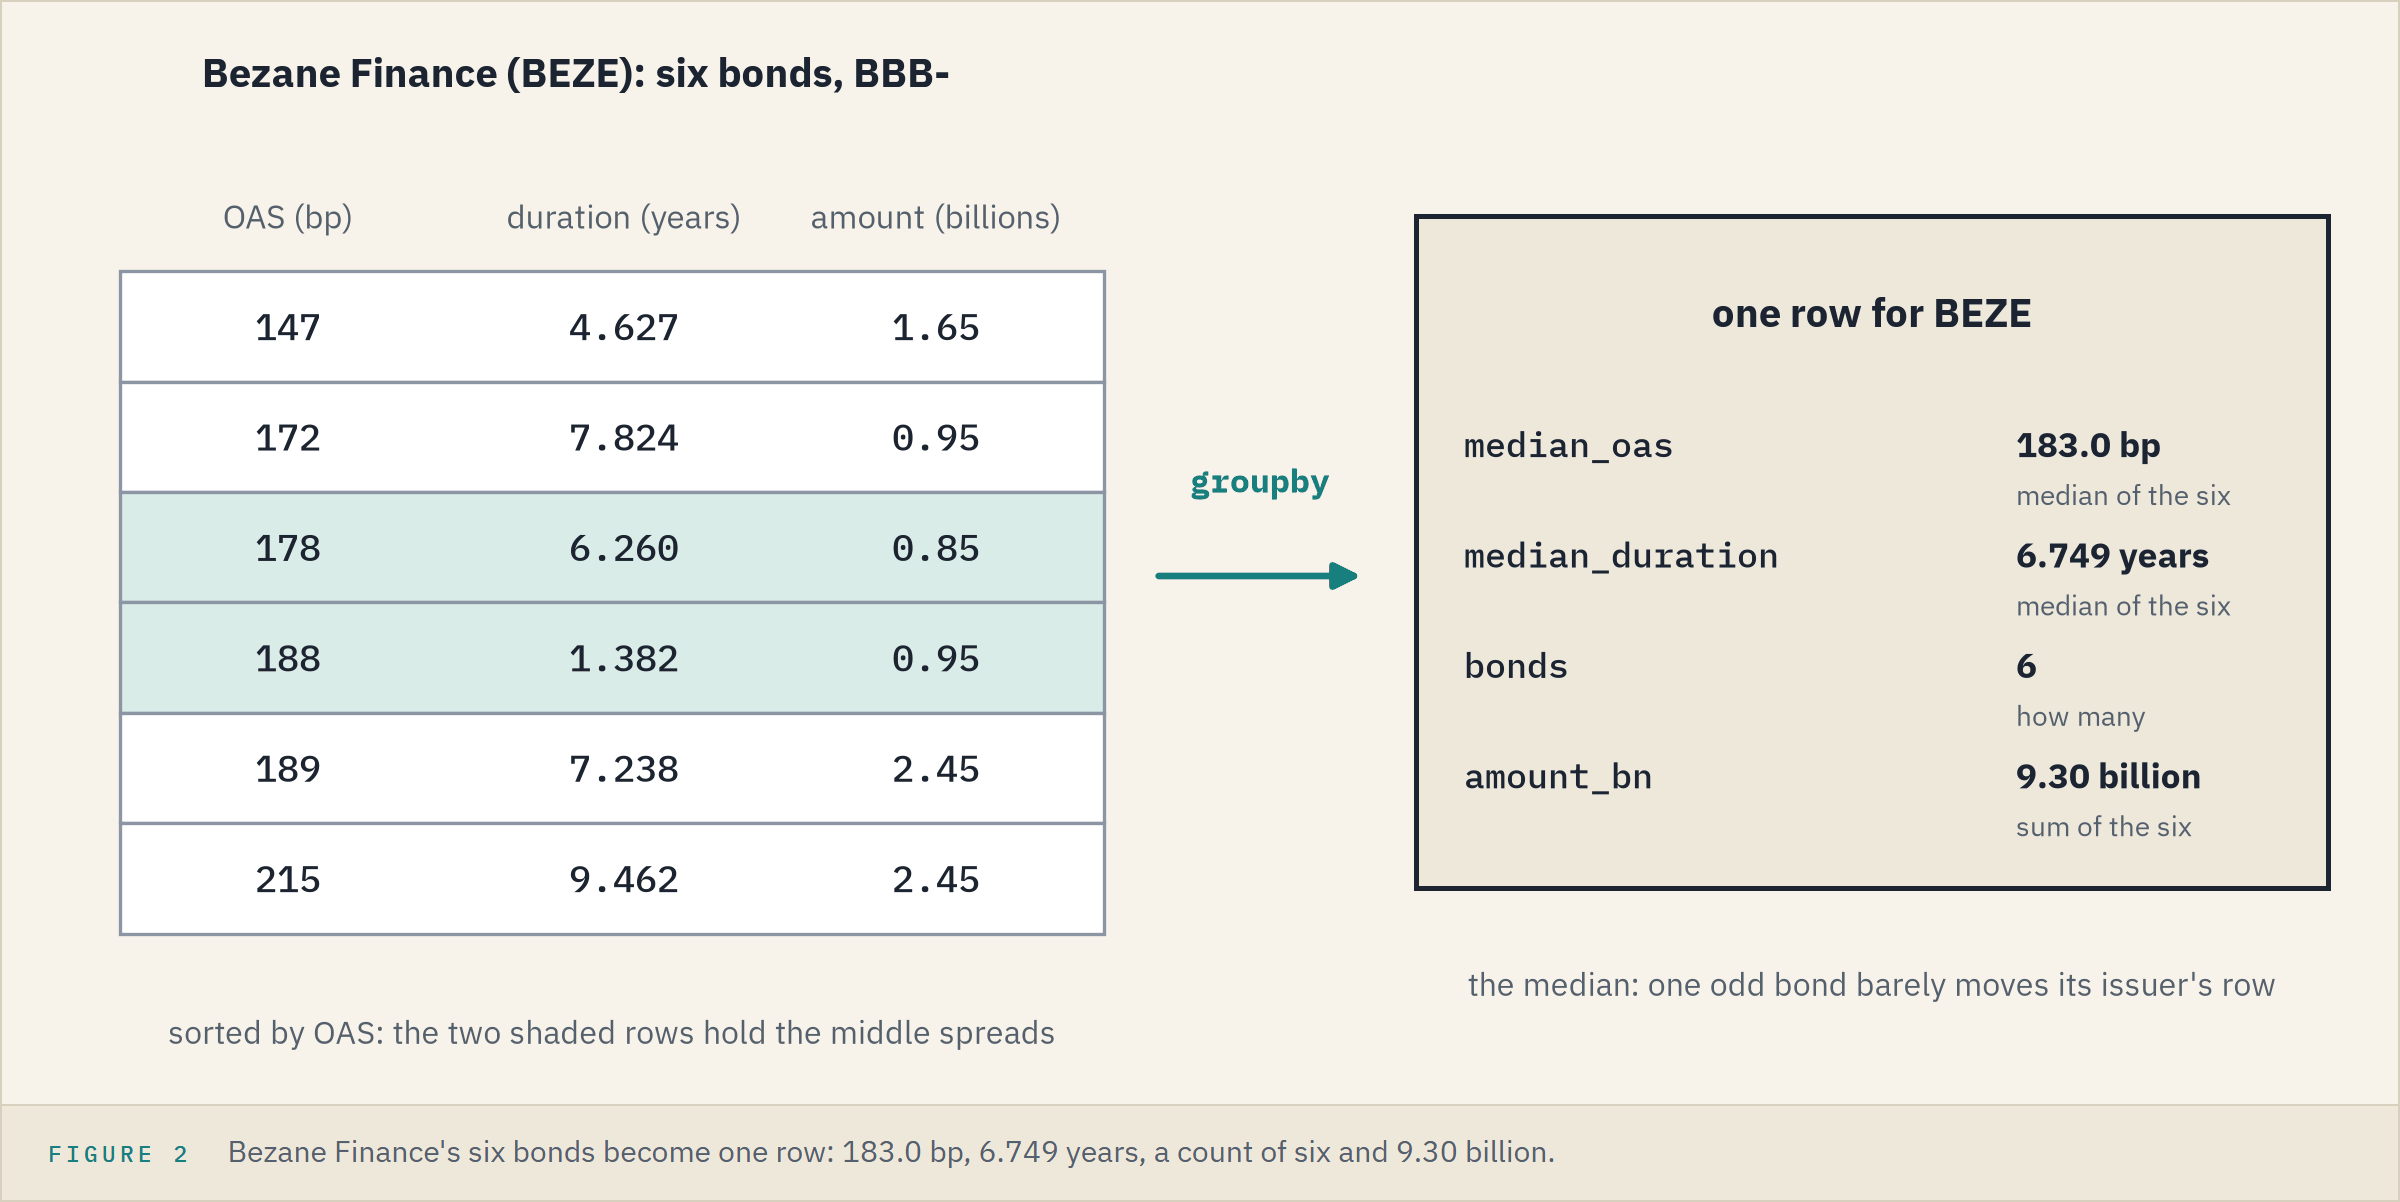

Today the rows are issuers, not bonds.
Each issuer's bonds collapse into one row: the median spread and duration, how many bonds, and their total size.

In [4]:
# one row per issuer: the medians of its bonds' spread and duration, its number of bonds, its total face value
issuers = bonds.groupby("ticker").agg(median_oas=("oas", "median"), median_log_oas=("log_oas", "median"),
                                      median_duration=("duration", "median"), bonds=("cusip", "count"),
                                      amount_bn=("amount_outstanding", "sum"))
issuers["amount_bn"] = issuers["amount_bn"] / 1e9  # dollars into billions of dollars

# each issuer's name, sector and rating, then the rating's score and grade; the ticker back as the row label
issuers = issuers.reset_index().merge(names[["ticker", "issuer", "sector", "rating"]], on="ticker")
issuers = issuers.merge(ratings[["rating", "score", "grade"]], on="rating").set_index("ticker")
issuers.shape

(150, 10)

150 issuers, one row each.
The medians keep one unusual bond from moving its issuer's row much.

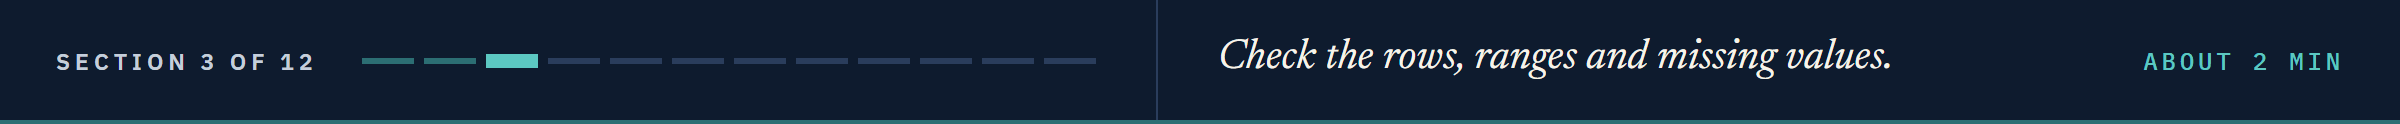

# Data Overview

## Checking the First Five Rows

In [5]:
# the first five issuers on the columns we read most
issuers[["sector", "rating", "median_oas", "median_duration", "bonds", "amount_bn"]].head()

,sector,rating,median_oas,median_duration,bonds,amount_bn
ticker,,,,,,
BEZE,Financials,BBB-,183.0,6.7490,6,9.3
BEZH,Industrials,B,372.0,5.1000,5,9.4
BEZL,Transportation,BB,194.0,5.4290,7,7.5
BEZN,Financials,BBB-,152.0,7.3380,5,6.0
BEZR,Utilities,A,82.5,3.3285,6,9.4


## Checking the Statistical Summary

Q. How far does each column spread across the issuers?

In [6]:
# count, mean, standard deviation and range of each column, one row per column
issuers[["median_oas", "median_log_oas", "median_duration", "bonds", "amount_bn", "score"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
median_oas,150.0,171.52,144.23,21.00,77.38,120.50,199.75,922.50
median_log_oas,150.0,4.88,0.71,3.04,4.35,4.79,5.29,6.83
median_duration,150.0,5.85,1.93,1.02,4.68,5.85,6.89,13.07
bonds,150.0,5.47,1.74,3.00,4.00,5.50,7.00,8.00
amount_bn,150.0,7.62,2.79,1.70,5.51,7.48,9.69,15.00
score,150.0,9.21,3.53,1.00,7.00,9.00,11.00,18.00


Median OAS runs from 21 to 922.5 bp, and every issuer has 3 to 8 bonds.

The total size runs from 1.70 to 15.00 billion, and the score covers the whole scale, 1 to 18.

## Checking for Missing and Duplicate Values

In [7]:
# missing values anywhere in the table, and tickers that appear twice
print(issuers.isnull().sum().sum(), issuers.index.duplicated().sum())

0 0


No missing values and no ticker twice.

**150 clean issuers, five columns on five scales. Day 12 showed what that does to a distance, so we will scale.**

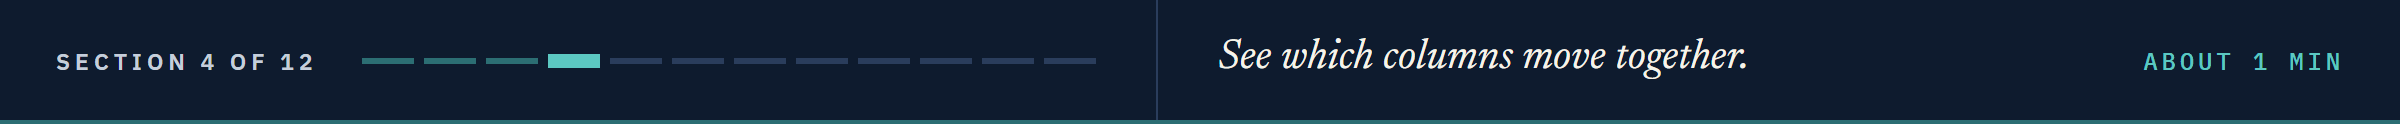

# Exploratory Data Analysis

## Five Columns, Pair by Pair

Q. Which of the five columns move together?

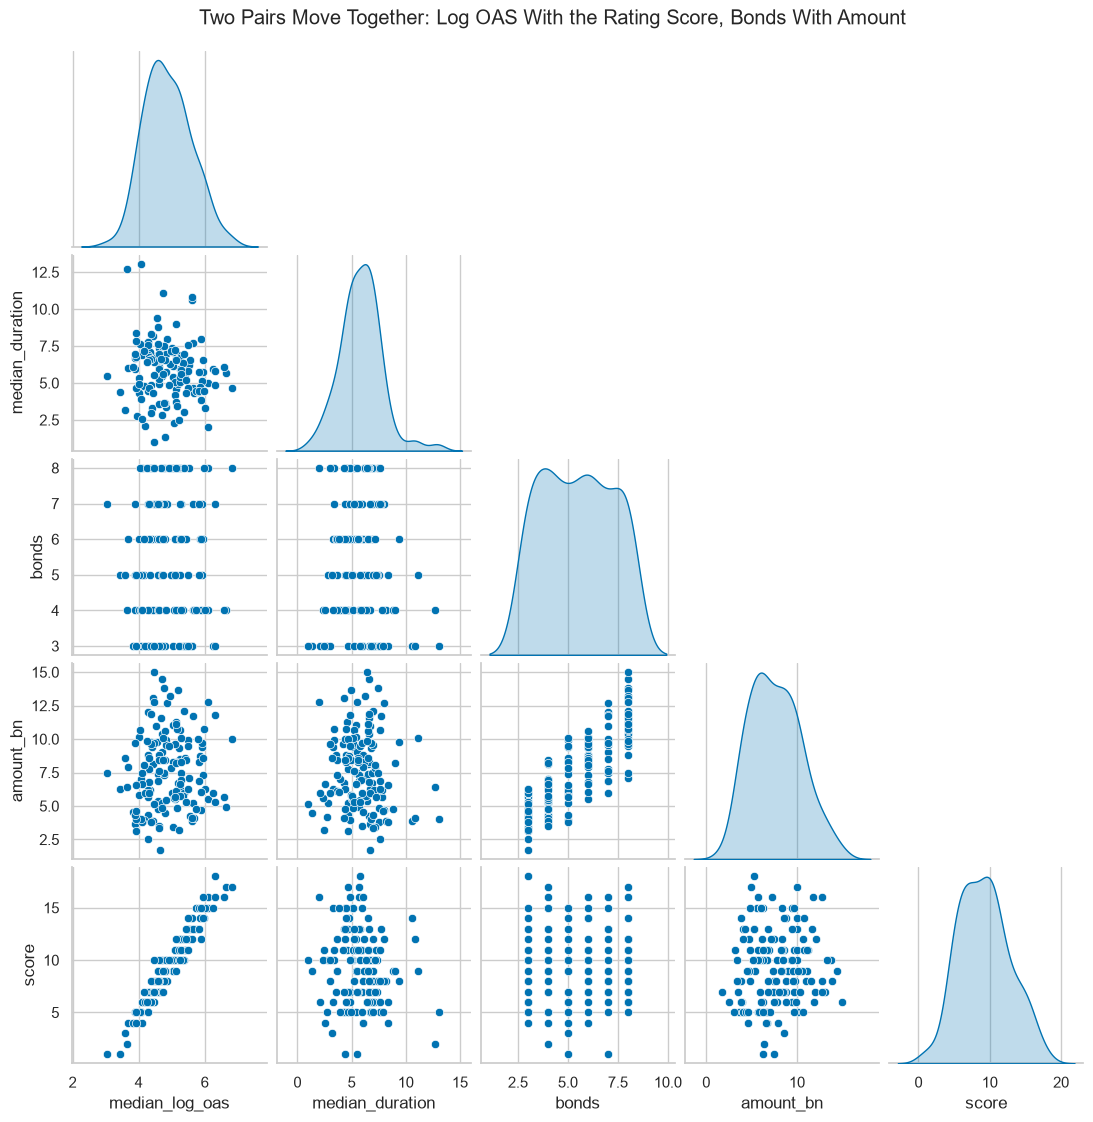

0.97 0.82


In [8]:
# every pair of the five columns, each pair drawn once; diag_kind="kde" puts a smooth curve of each column on the diagonal
features = ["median_log_oas", "median_duration", "bonds", "amount_bn", "score"]
sns.pairplot(issuers[features], corner=True, diag_kind="kde", height=2.2)
plt.suptitle("Two Pairs Move Together: Log OAS With the Rating Score, Bonds With Amount", y=1.02)
plt.show()

# the two tightest pairs, as correlations
correlations = issuers[features].corr()
print(round(correlations.loc["median_log_oas", "score"], 2), round(correlations.loc["bonds", "amount_bn"], 2))

Log OAS and the rating score lie almost on a line: correlation 0.97.

The number of bonds and the total size move together too: 0.82.

Duration has nothing to do with either pair.

**Two columns say credit and two say size, so a distance will hear credit twice. We keep that in mind and measure distance.**

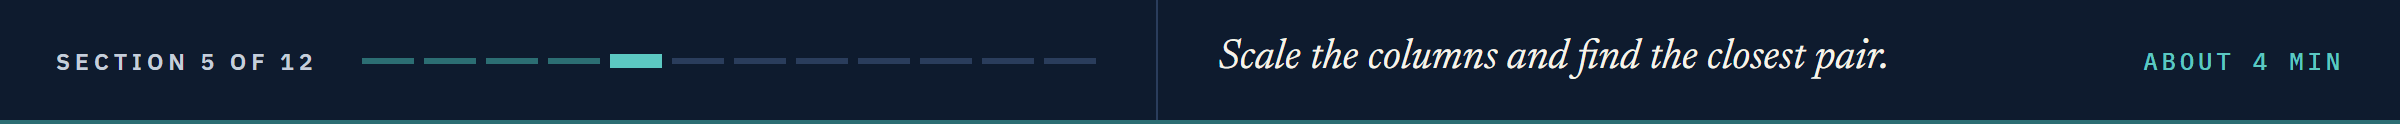

# Distance Between Two Issuers

## Scaling the Columns

Day 5's `StandardScaler`, which Day 12 used before measuring distance, turns each column into its z-score, so a gap of 1 is one standard deviation on any column.
`scale_` holds the standard deviation it divided each column by.

In [9]:
# scale the five columns over all 150 issuers, keeping the tickers as row labels
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(issuers[features]), columns=features, index=issuers.index)

# one standard deviation of each column, in its own unit
pd.Series(scaler.scale_, index=features).round(2)

median_log_oas     0.71
median_duration    1.93
bonds              1.73
amount_bn          2.78
score              3.52
dtype: float64

One standard deviation is 0.71 log points of OAS, 1.93 years, 1.73 bonds, 2.78 billion and 3.52 notches.
The scaler divides by the number of rows, not one less, so bonds reads 1.73 here and 1.74 in the summary.

## The First Two Issuers by Hand

In [10]:
# the gap between BEZE and BEZH on each scaled column
gaps = X_scaled.loc["BEZH"] - X_scaled.loc["BEZE"]
print(gaps.round(3).to_dict())

# square the gaps, add them up, take the square root: Day 12's distance
print("Distance:", round(np.sqrt((gaps ** 2).sum()), 4))

{'median_log_oas': 1.003, 'median_duration': -0.856, 'bonds': -0.576, 'amount_bn': 0.036, 'score': 1.421}
Distance: 2.0227


BEZE and BEZH are 2.0227 apart, most of it from log OAS and the score: credit, heard twice.

## Every Pair at Once

`pdist` gives every pair's distance as one long list, and `squareform` lays the list out as a table.

In [11]:
# the distance between every pair of the 150 issuers
pair_distances = pdist(X_scaled)
print(len(pair_distances), "pairs; median", round(np.median(pair_distances), 2), "; largest", round(pair_distances.max(), 2))

# the same distances as a 150 by 150 table, one row and one column per issuer
distances = pd.DataFrame(squareform(pair_distances), index=issuers.index, columns=issuers.index)
distances.iloc[:4, :4].round(4)

11175 pairs; median 2.86 ; largest 8.31


ticker,BEZE,BEZH,BEZL,BEZN
ticker,,,,
BEZE,0.0000,2.0227,1.2449,1.3783
BEZH,2.0227,0.0000,1.8432,2.5416
BEZL,1.2449,1.8432,0.0000,1.7445
BEZN,1.3783,2.5416,1.7445,0.0000


11,175 pairs, a median distance of 2.86 and a largest of 8.31.
The table reads both ways, and each issuer is 0 from itself.

## The Closest Two Issuers

**Predict 1**

Q. The two closest issuers of the 150: which of the five columns will they share exactly?

In [12]:
# keep the gaps between two different issuers; stack() turns the table into one long list of pairs, idxmin() finds the smallest
closest = distances[distances > 0].stack().idxmin()
print(closest, round(distances.loc[closest], 4))
issuers.loc[list(closest), ["issuer", "sector", "rating", "median_oas", "median_duration", "bonds", "amount_bn"]]

('CLAY', 'WYXR') 0.2075


,issuer,sector,rating,median_oas,median_duration,bonds,amount_bn
ticker,,,,,,,
CLAY,Clavolvey Bancorp,Financials,BB+,221.5,5.611,6,8.60
WYXR,Wyximer Wireless,Telecom,BB+,197.5,5.580,6,8.25


Clavolvey Bancorp (CLAY) and Wyximer Wireless (WYXR) are 0.2075 apart.

They share the rating and the number of bonds exactly: the two columns that move in whole steps.

A bank and a telecom: the sector was never in the distance.

**The closest two issuers are where the tree begins.**

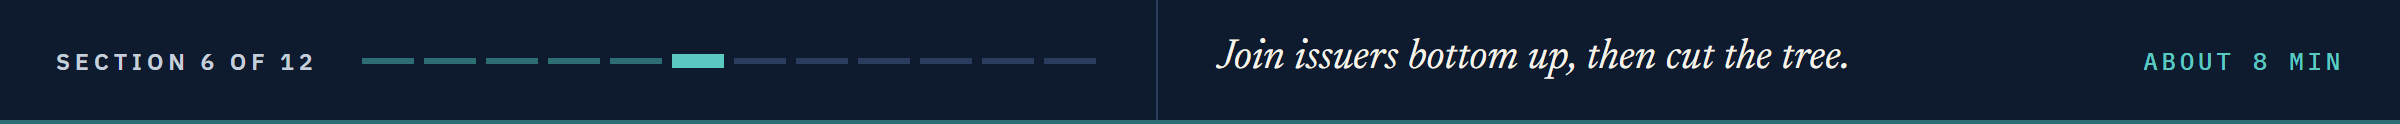

# Building the Tree

## How Hierarchical Clustering Works

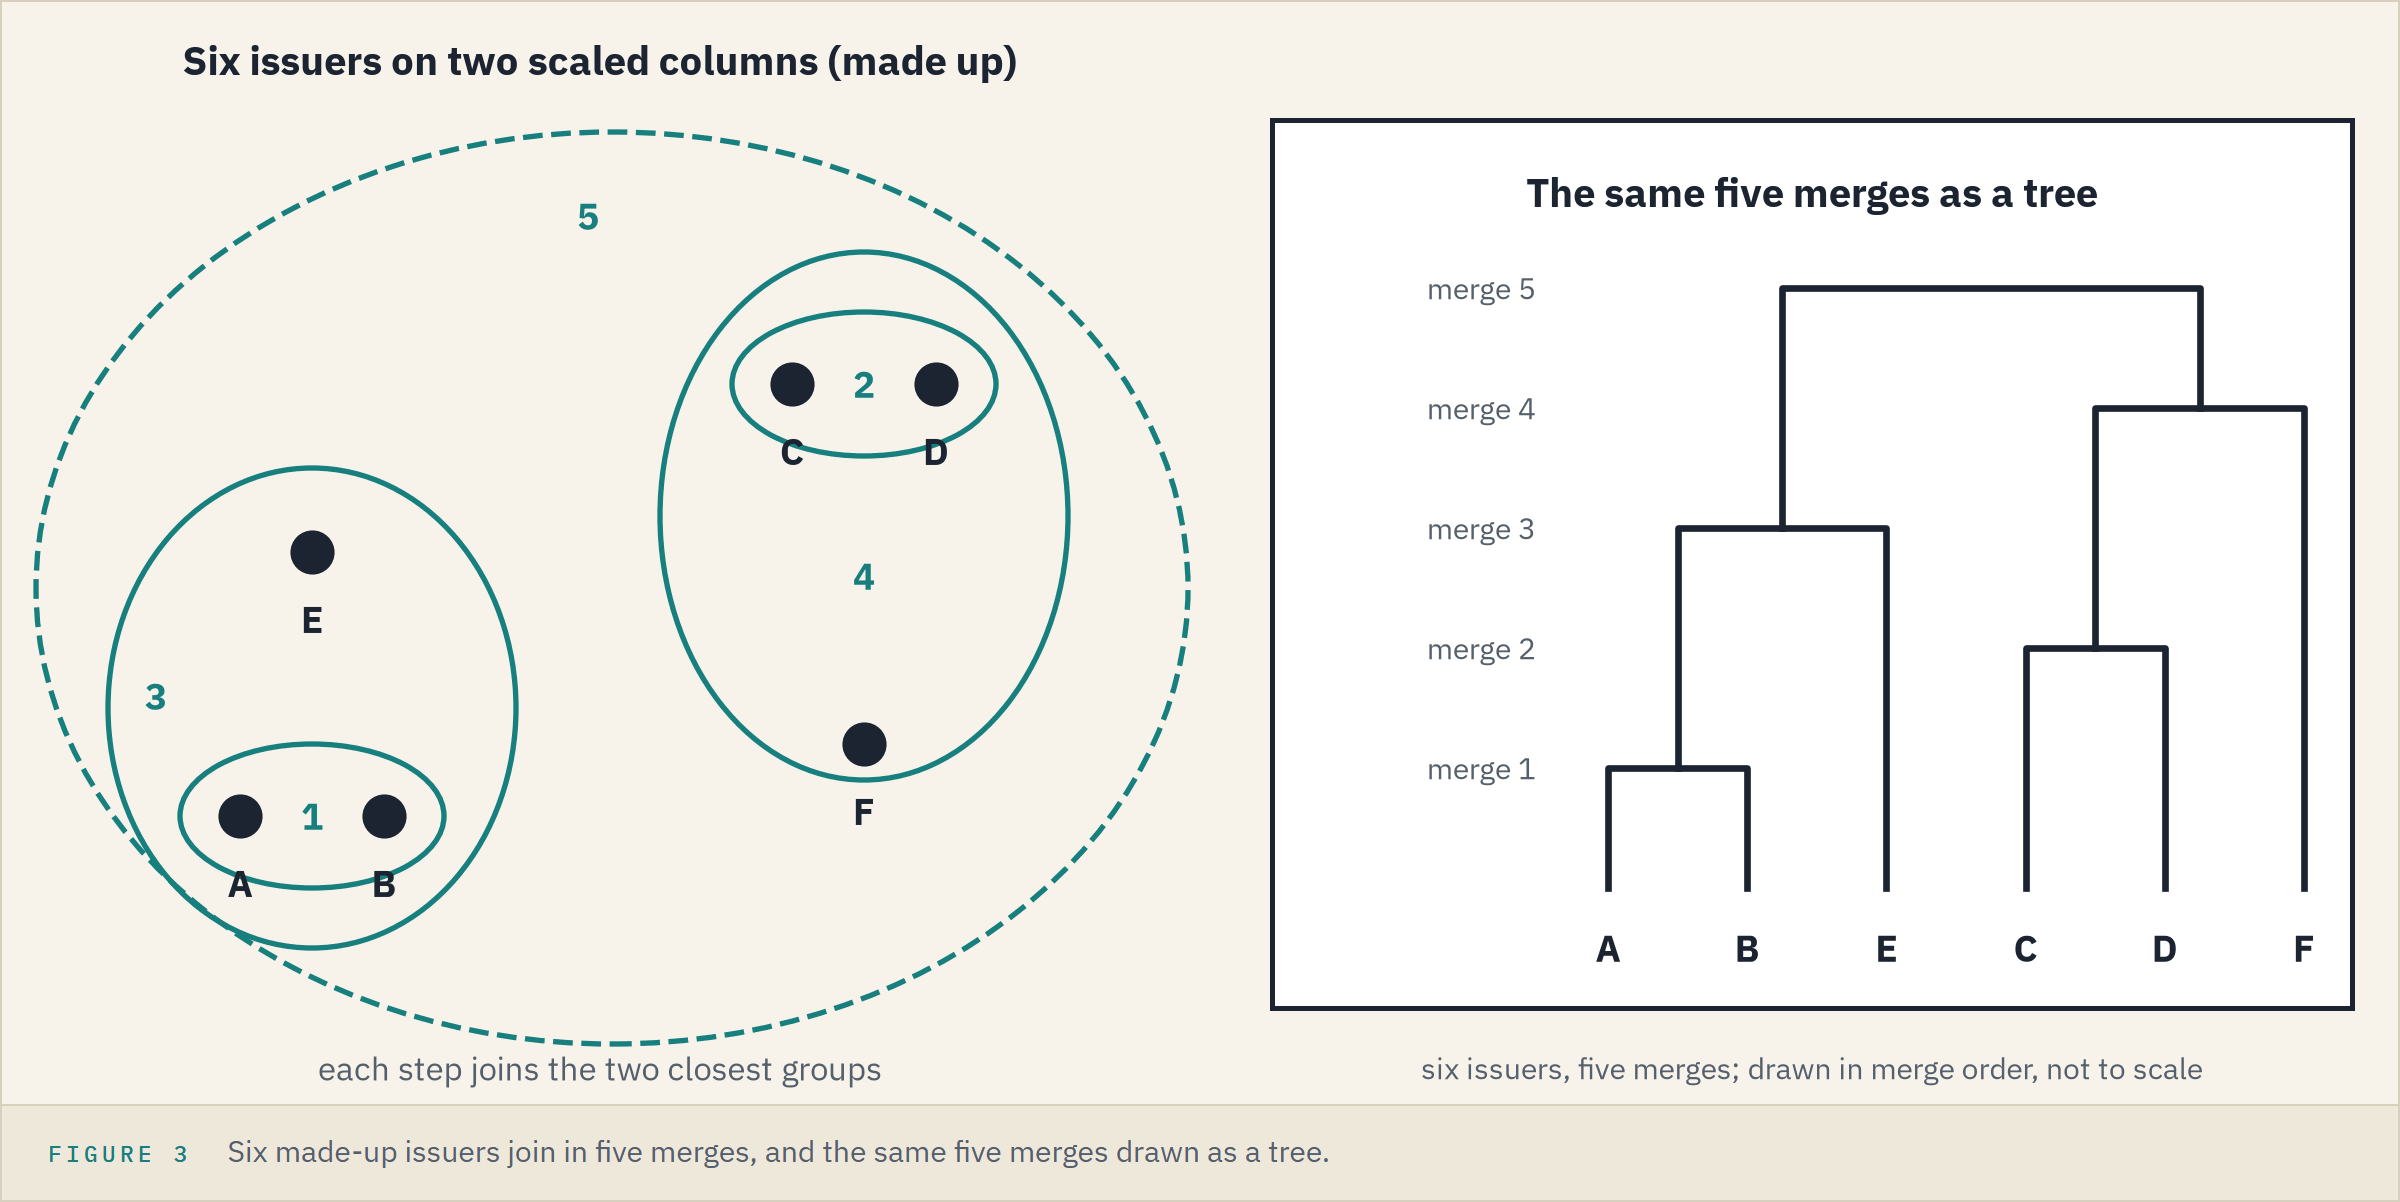

**Hierarchical clustering** starts with every issuer as its own cluster and joins the two closest clusters, again and again, until one is left.
Building from the bottom up like this is called **agglomerative**.

Each join is a **merge**; the gap at which it happens is its **merge height**.

150 issuers take 149 merges.

There is no k and no seed: the same rows give the same tree on every run.

## Every Merge in One Table

`linkage` makes every merge at once.
`method="ward"` joins, at each step, the two clusters whose merge adds the least spread around the new cluster's centre.

In [13]:
# every merge of the ward tree: one row per merge, in order
merges = linkage(X_scaled, method="ward")
print(merges.shape)

# a number below 150 is an issuer; 150 and up is the cluster made at merge (number - 150)
members = list(issuers.index) + [f"merge {i}" for i in range(149)]
table = pd.DataFrame(merges, columns=["first", "second", "height", "issuers"])
table["first"] = [members[int(i)] for i in table["first"]]
table["second"] = [members[int(i)] for i in table["second"]]
table.head(8).round(4)

(149, 4)


,first,second,height,issuers
0,CLAY,WYXR,0.2075,2.0
1,ELVX,GALY,0.2586,2.0
2,BEZN,VYRN,0.3289,2.0
3,THAX,XANH,0.3628,2.0
4,HESA,KEZA,0.4167,2.0
5,CLAL,YARN,0.4331,2.0
6,FESR,NEVN,0.4447,2.0
7,CLAX,ELVN,0.4491,2.0


In [14]:
# the first merge that joins a single issuer to a cluster already made
table[table["issuers"] > 2].head(1).round(4)

,first,second,height,issuers
42,RULE,merge 19,0.7167,3.0


149 merges, one row each: the two members joined, the height, and the issuers in the new cluster.

Merge 0 joins CLAY and WYXR at 0.2075, their distance.

Merges 0 to 41 each join two single issuers; merge 42 is the first to grow a cluster, adding RULE to the pair made at merge 19.

## How High the Merges Climb

**Predict 2**

Q. Sketch the 149 merge heights in order, merge number along the bottom. What shape do they make?

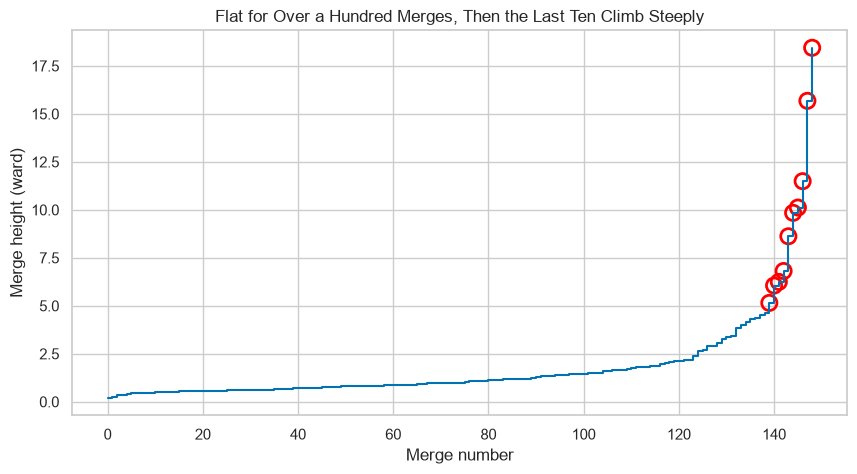

117 of 149 merges below 2; 139 below 5; the last at 18.44


In [15]:
# merge heights in order, as steps; the last ten merges ringed in red
heights = table["height"]
plt.step(table.index, heights, where="post")
plt.scatter(table.index[-10:], heights[-10:], s=120, facecolors="none", edgecolors="red", linewidths=2)
plt.xlabel("Merge number")
plt.ylabel("Merge height (ward)")
plt.title("Flat for Over a Hundred Merges, Then the Last Ten Climb Steeply")
plt.show()
print((heights < 2).sum(), "of 149 merges below 2;", (heights < 5).sum(), "below 5; the last at", round(heights.iloc[-1], 2))

The heights stay low and nearly flat: 117 of 149 merges happen below 2.

The last ten merges climb steeply, to 18.44 for the last.

A big jump means the merge joined two groups that were far apart.

## The Dendrogram

A **dendrogram** draws the tree: each issuer is a leaf along the bottom, and each merge is a bar at its height.
A horizontal line across the tree is a **cut**: the branches it crosses are the clusters.

Cut at 10.81


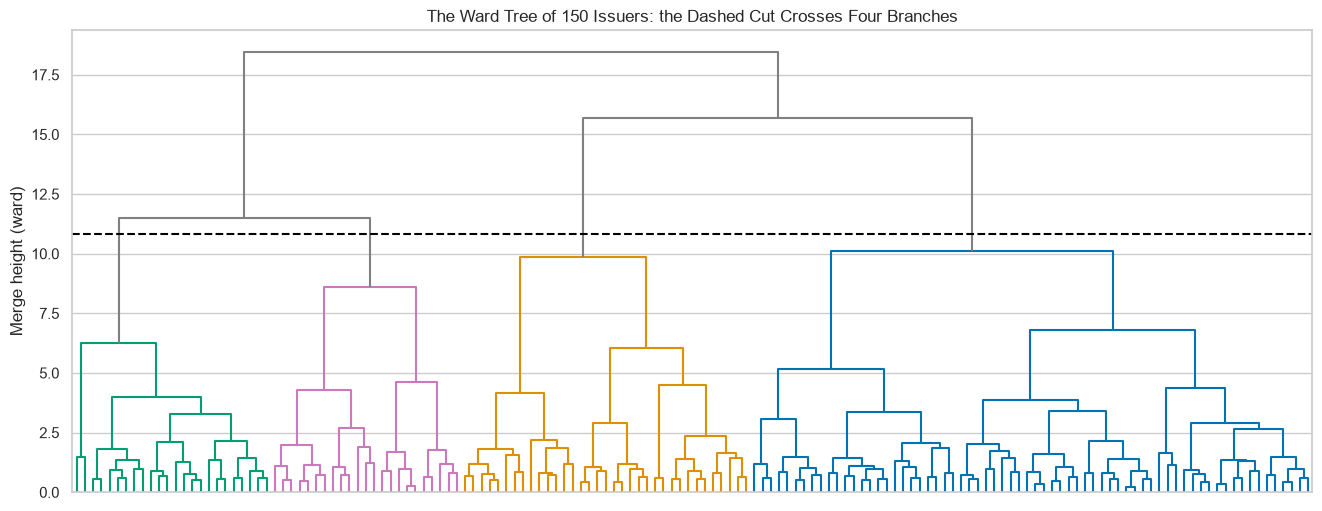

In [16]:
# a cut halfway between the fourth-last merge and the third-last crosses four branches
cut = (heights.iloc[-4] + heights.iloc[-3]) / 2
print("Cut at", round(cut, 2))

# set_link_color_palette sets the branch colours below the cut, left to right: here the colours of clusters 2, 3, 1 and 0
set_link_color_palette([colours[2], colours[3], colours[1], colours[0]])
# color_threshold colours the branches below the cut, the rest take above_threshold_color; no_labels leaves off the tickers
plt.figure(figsize=(16, 6))
dendrogram(merges, color_threshold=cut, above_threshold_color="gray", no_labels=True)
plt.axhline(cut, color="black", linestyle="--")
plt.ylabel("Merge height (ward)")
plt.title("The Ward Tree of 150 Issuers: the Dashed Cut Crosses Four Branches")
plt.show()

The dashed cut at 10.81 crosses four stems, so it leaves four clusters.

Above the cut the tree is gray: those are the merges the cut undoes.

The long gray stems show the big jumps of the last merges.

## Cutting the Tree With `fcluster`

`fcluster` gives each issuer its cluster: `criterion="maxclust"` asks for a number of clusters, `criterion="distance"` for a cut height.

In [17]:
# four clusters by count, and the same tree cut at height 10.81
by_count = fcluster(merges, t=4, criterion="maxclust")
by_height = fcluster(merges, t=cut, criterion="distance")
print("Same labels:", (by_count == by_height).all())

Same labels: True


In [18]:
# Day 12's numbering: the largest cluster becomes cluster 0
def by_size(labels):
    sizes = pd.Series(labels).value_counts()
    new_number = {old: new for new, old in enumerate(sizes.index)}
    return pd.Series(labels).map(new_number)

issuers["cluster"] = by_size(by_count).to_numpy()
issuers["cluster"].value_counts()

cluster
0    68
1    35
2    24
3    23
Name: count, dtype: int64

In [19]:
# scikit-learn's version of the same tree, cut at four clusters, against ours
agg = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X_scaled)
pd.crosstab(issuers["cluster"], agg.labels_, rownames=["scipy"], colnames=["scikit-learn"])

scikit-learn,0,1,2,3
scipy,,,,
0,68,0,0,0
1,0,0,35,0
2,0,0,0,24
3,0,23,0,0


Four clusters of 68, 35, 24 and 23 issuers: from left to right in the dendrogram, clusters 2, 3, 1 and 0.

Each row of the crosstab has one full cell: `AgglomerativeClustering` finds the same four groups under other numbers.

## The Tree and the Data Together

Q. What made each cluster?
A **clustermap** draws the scaled table as coloured cells, rows in the tree's order, with the tree beside it.

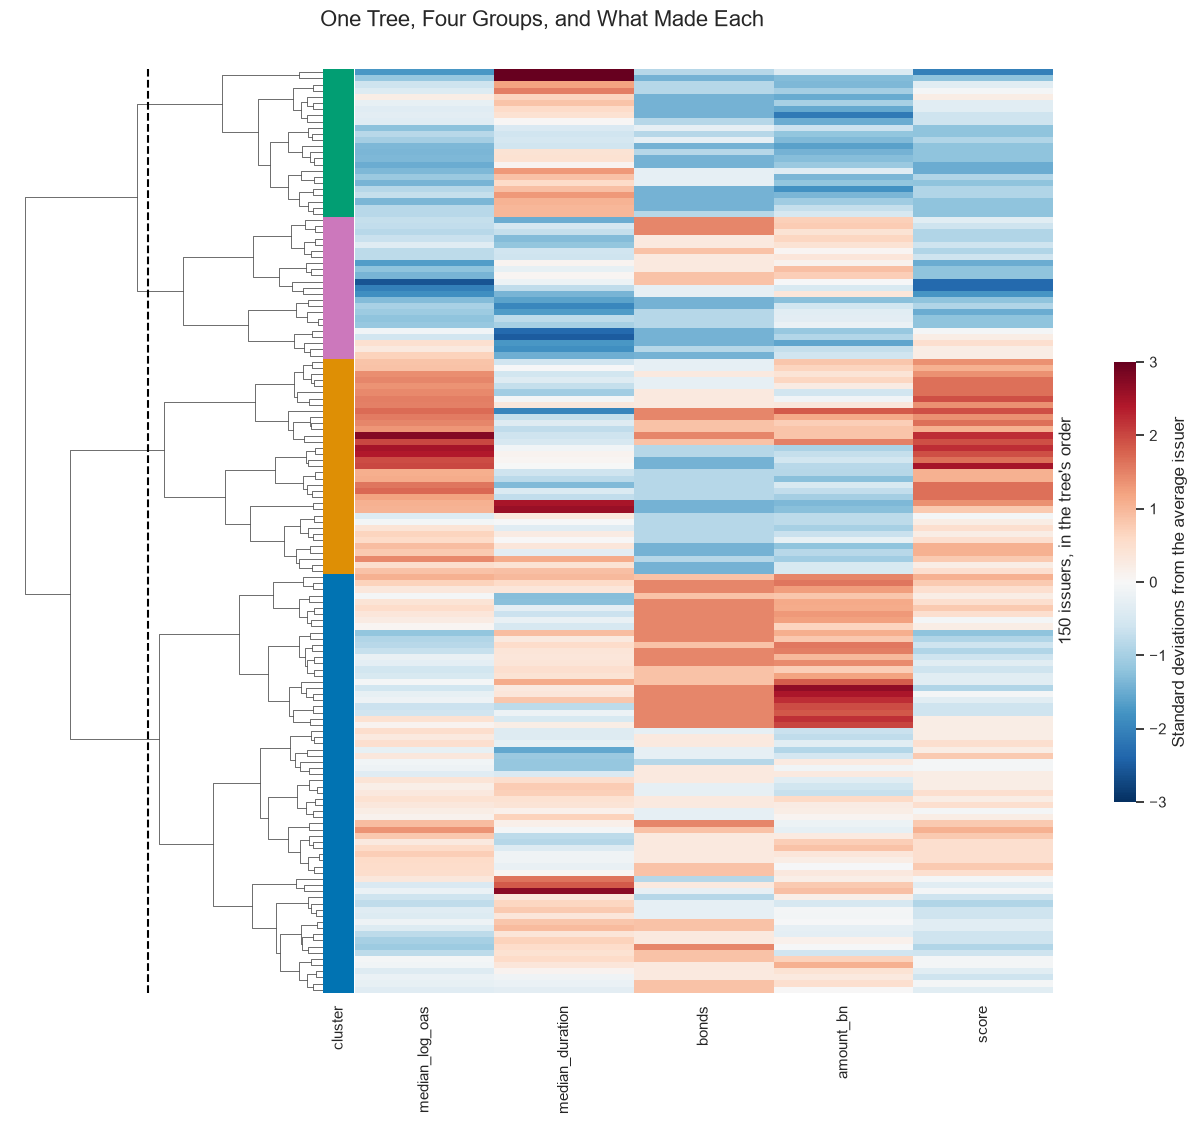

In [20]:
# the scaled table in the tree's order: red above the average issuer, blue below; the ward tree down the left
# dendrogram_ratio sets the room the tree takes, cbar_pos where the colour bar sits
strip = pd.Series([colours[c] for c in issuers["cluster"]], index=issuers.index, name="cluster")
grid = sns.clustermap(X_scaled, row_linkage=merges, col_cluster=False, row_colors=strip, cmap="RdBu_r", center=0,
                      vmin=-3, vmax=3, yticklabels=False, figsize=(11, 11), dendrogram_ratio=(0.3, 0.02),
                      cbar_pos=(1.02, 0.3, 0.02, 0.4), cbar_kws={"label": "Standard deviations from the average issuer"})
# the same cut on the tree; the tree lies on its side, so the cut is a vertical line
grid.ax_row_dendrogram.axvline(cut, color="black", linestyle="--")
grid.ax_heatmap.set_ylabel("150 issuers, in the tree's order")
grid.figure.suptitle("One Tree, Four Groups, and What Made Each", y=1.02, fontsize=16)
plt.show()

In [21]:
# each cluster's average on the five scaled columns: the bands of the map in numbers
means = X_scaled.groupby(issuers["cluster"]).mean()
means.round(2)

,median_log_oas,median_duration,bonds,amount_bn,score
cluster,,,,,
0,-0.03,0.16,0.64,0.58,-0.03
1,1.28,-0.12,-0.44,-0.23,1.28
2,-0.92,0.81,-1.02,-1.20,-0.95
3,-0.90,-1.12,-0.17,-0.11,-0.88


Cluster 1, the orange strip, is red on log OAS and the score: +1.28 on both.

Cluster 0, the blue strip, is red on bonds and amount, +0.64 and +0.58, and near 0 on credit.

Clusters 2 and 3, green and pink, are blue on credit, about -0.9 each, and split by duration: +0.81 against -1.12.

Cluster 2 is also small: -1.02 on bonds and -1.20 on amount.

**One tree, four groups, and you can see what made each. Next: why four, and not three or six.**

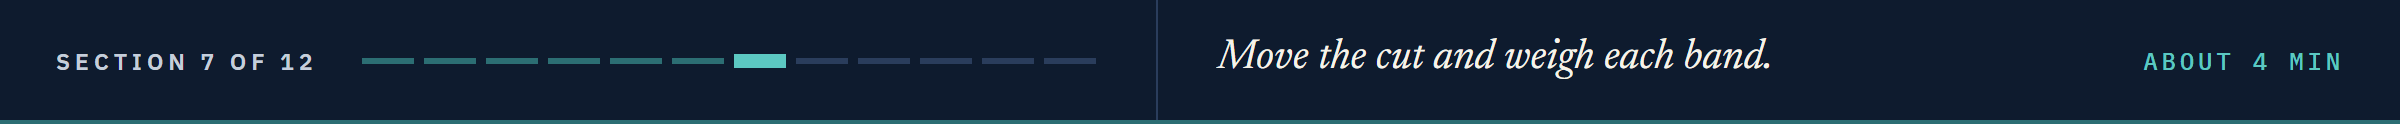

# Where to Cut

## Move the Cut Yourself

A cut can sit at any height, so the tree holds every number of clusters at once.
`truncate_mode="lastp"` draws only the tree's top `p` branches, each one's issuer count in brackets.

In [22]:
# one cut drawn on one set of axes: the issuers on median OAS and duration, coloured by their cluster
def draw_cut(ax, k):
    clusters = by_size(fcluster(merges, t=k, criterion="maxclust"))
    ax.scatter(issuers["median_oas"], issuers["median_duration"], c=[colours[c] for c in clusters], s=30)
    ax.set_xscale("log")
    ax.set_title(f"{k} clusters: sizes {clusters.value_counts().tolist()}")
    ax.set_xlabel("Median OAS (bp, log scale)")
    ax.set_ylabel("Median duration (years)")

In [23]:
# your turn: move the cut from 2 clusters to 8
def move_cut(k=4):
    fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5))
    height = (heights.iloc[-k] + heights.iloc[-k + 1]) / 2
    # color_threshold=0 draws every branch gray
    dendrogram(merges, truncate_mode="lastp", p=20, color_threshold=0, above_threshold_color="gray", ax=left)
    left.axhline(height, color="black", linestyle="--")
    left.set_title(f"Cut at height {height:.2f}")
    draw_cut(right, k)
    plt.show()

interact(move_cut, k=(2, 8, 1));

interactive(children=(IntSlider(value=4, description='k', max=8, min=2), Output()), _dom_classes=('widget-inte…

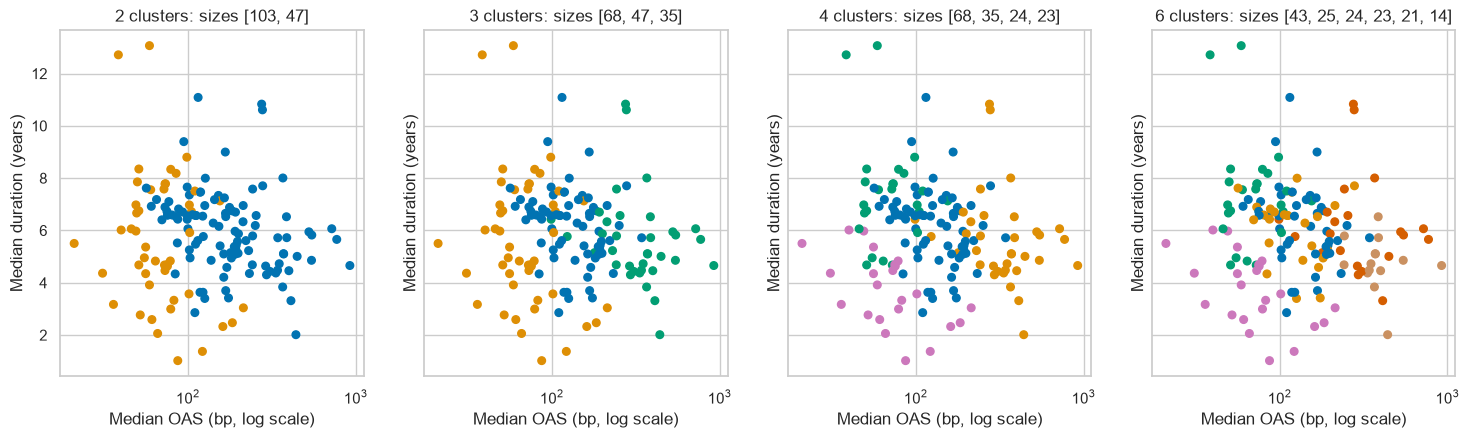

In [24]:
# cuts at 2, 3, 4 and 6 clusters side by side, drawn as a still picture (sliders do not run on GitHub)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, k in zip(axes, [2, 3, 4, 6]):
    draw_cut(ax, k)
plt.show()

Two clusters split 47 tight-spread issuers from the other 103.

The third cut splits the 103 into 68 and 35.

The fourth splits the 47 tighter issuers into a longer and a shorter group.

At 6, the two largest split again, down to a cluster of 14.

## How Far the Cut Can Move

Q. Over what range of heights does a cut give each number of clusters?

In [25]:
# for each number of clusters, the band of heights where a cut gives it; Day 12's silhouette beside it
bands = pd.DataFrame({"k": range(2, 11)})
bands["low"] = [heights.iloc[-k] for k in bands["k"]]
bands["high"] = [heights.iloc[-k + 1] for k in bands["k"]]
bands["width"] = bands["high"] - bands["low"]
bands["silhouette"] = [silhouette_score(X_scaled, fcluster(merges, t=k, criterion="maxclust")) for k in bands["k"]]
bands.round(3)

,k,low,high,width,silhouette
0,2,15.680,18.444,2.764,0.227
1,3,11.493,15.680,4.187,0.212
2,4,10.119,11.493,1.374,0.215
3,5,9.843,10.119,0.275,0.197
4,6,8.622,9.843,1.221,0.212
5,7,6.813,8.622,1.809,0.227
6,8,6.245,6.813,0.568,0.215
7,9,6.055,6.245,0.190,0.228
8,10,5.151,6.055,0.905,0.231


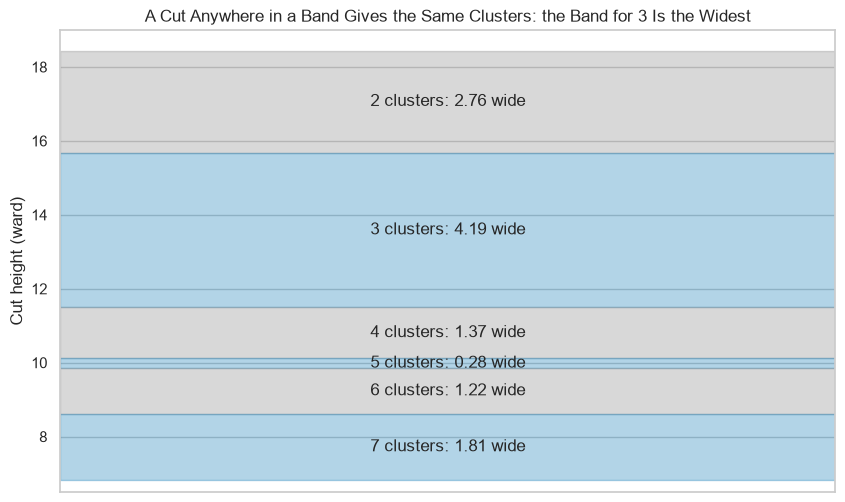

In [26]:
# each band shaded, gray and blue in turn, and named by the clusters a cut inside it gives
fig, ax = plt.subplots(figsize=(10, 6))
for k, low, high in zip(bands["k"][:6], bands["low"], bands["high"]):
    ax.axhspan(low, high, color=colours[0] if k % 2 else "gray", alpha=0.3)
    ax.text(0.5, (low + high) / 2, f"{k} clusters: {high - low:.2f} wide", ha="center", va="center", fontsize=12)
ax.set_ylim(6.5, 19)
ax.set_xticks([])
ax.set_ylabel("Cut height (ward)")
ax.set_title("A Cut Anywhere in a Band Gives the Same Clusters: the Band for 3 Is the Widest")
plt.show()

A cut anywhere from 11.49 to 15.68 gives 3 clusters: the widest band, 4.19.

The band for 4 is 1.37 wide, narrower than those for 2 and 7.

Day 12's silhouette barely moves, 0.197 to 0.231 for 2 to 10 clusters.

**The widest band says 3 and the silhouette says almost nothing. We take 4, because the fourth cluster splits the tighter issuers by duration: a judgement, stated as one.**

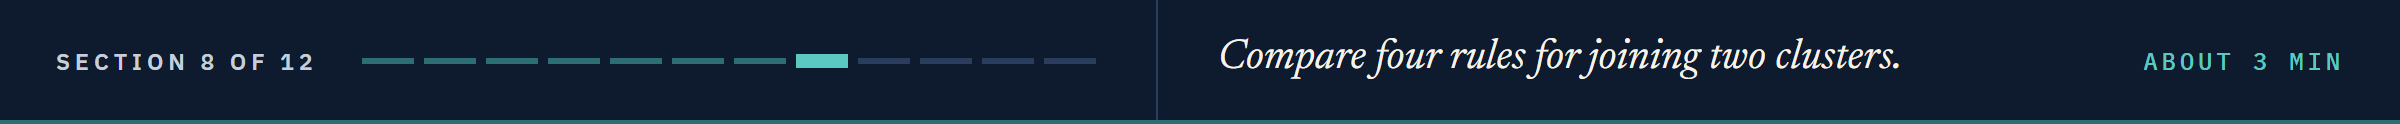

# Four Linkages, Four Trees

## What Close Means for a Group

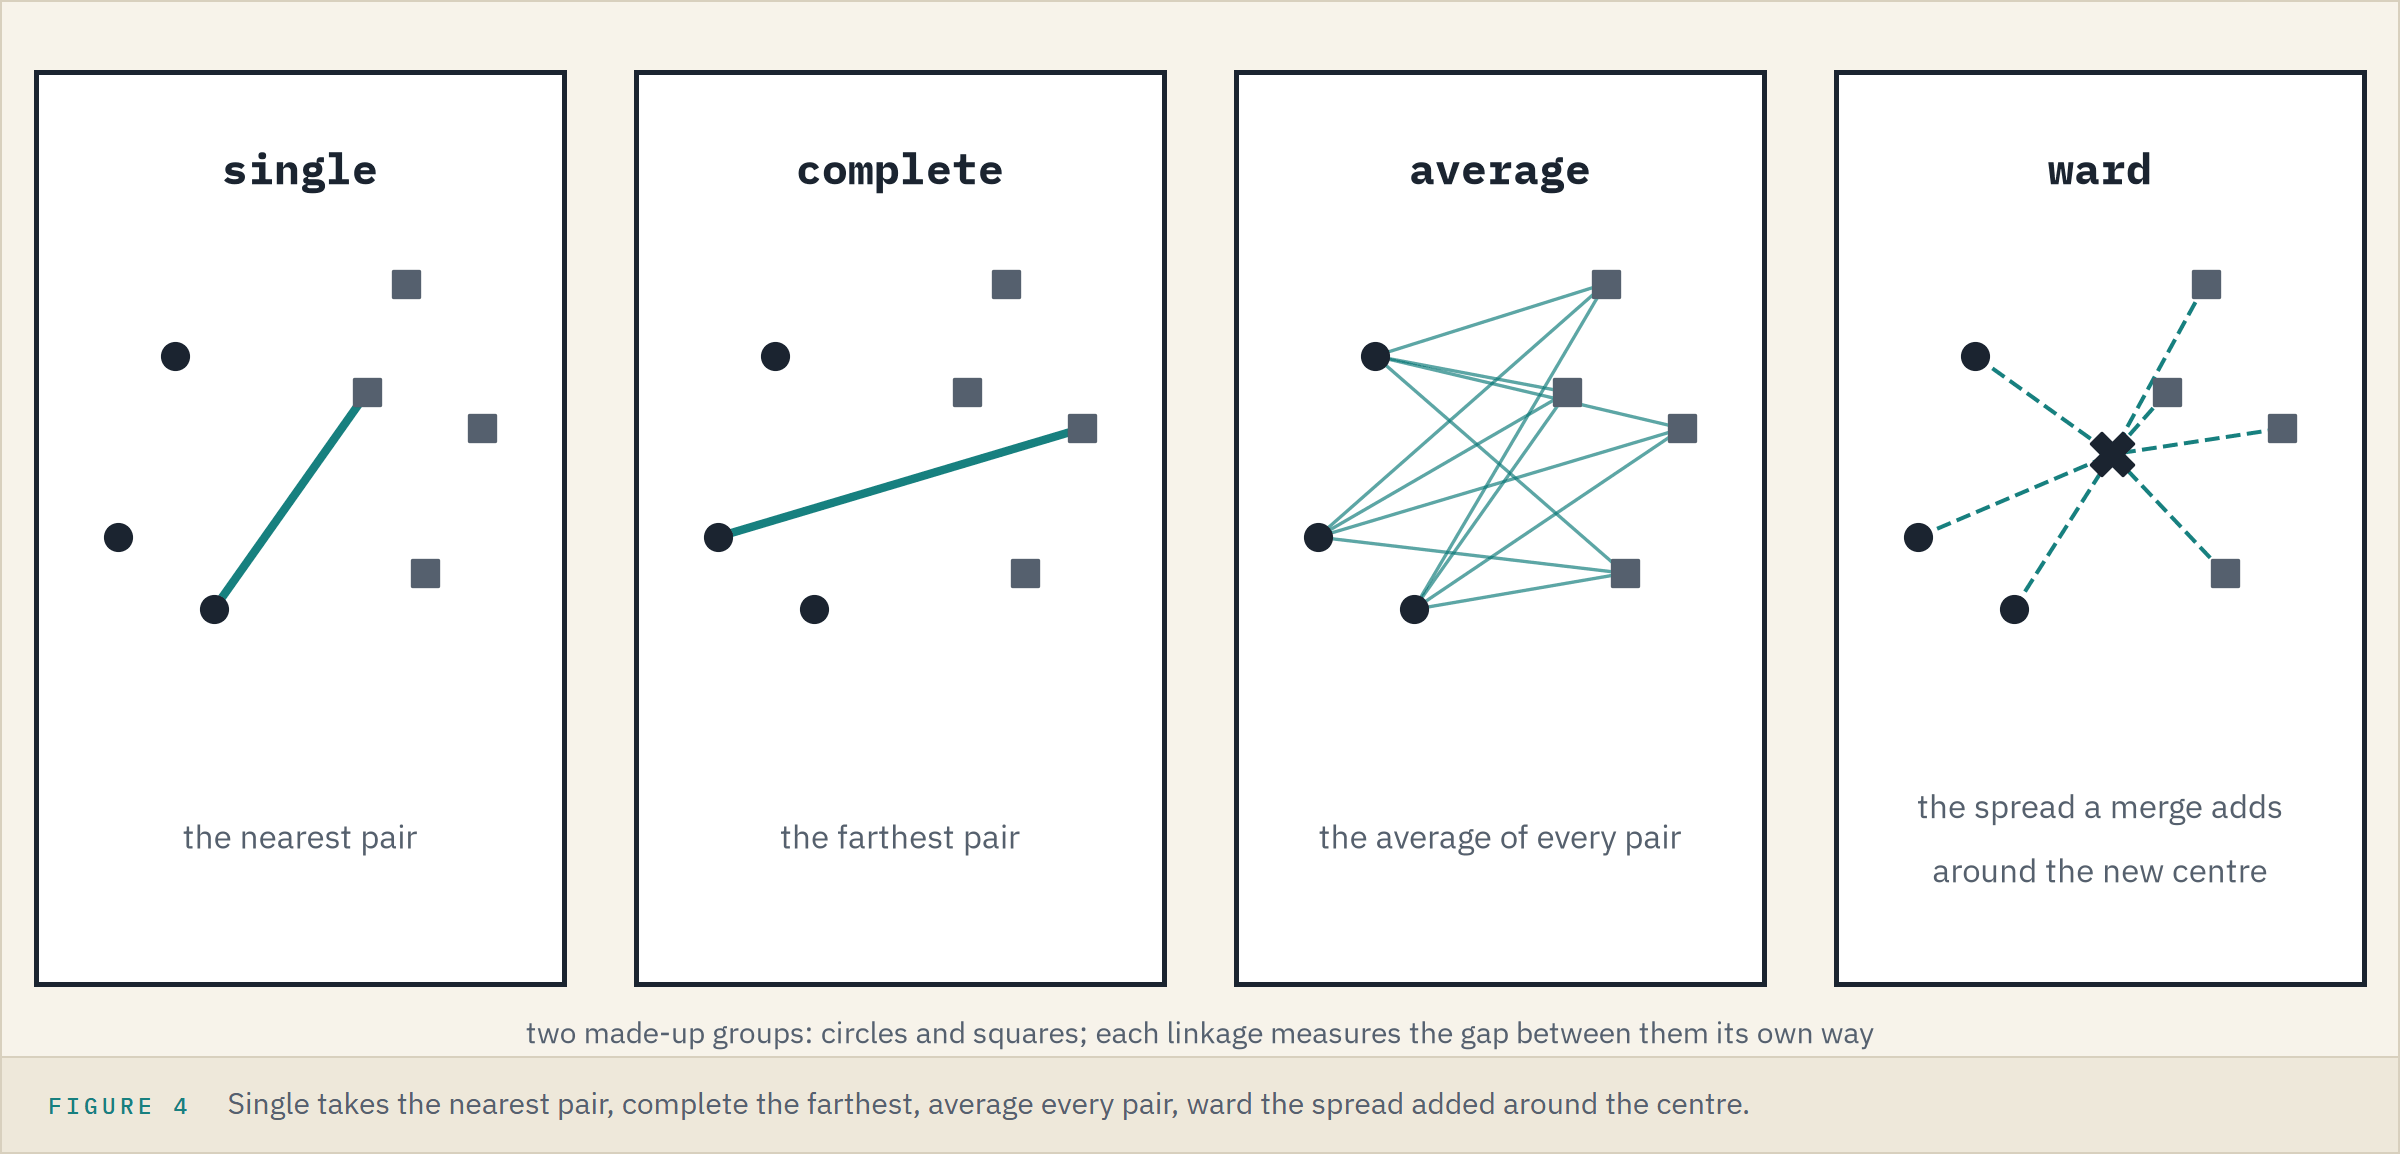

Ward is one rule for how close two clusters are; a **linkage** is that rule.

* **single**: the distance of the nearest pair across the two clusters
* **complete**: the distance of the farthest pair
* **average**: the average distance over every pair
* **ward**: the spread the merge adds around the new centre

## Cluster Sizes by Linkage

**Predict 3**

Q. Cut the single linkage tree into four clusters. How many of the 150 issuers land in the largest?

In [27]:
# the same distances, four linkages, each tree cut into four clusters
trees, sizes = {}, {}
for method in ["single", "complete", "average", "ward"]:
    trees[method] = linkage(X_scaled, method=method)
    sizes[method] = by_size(fcluster(trees[method], t=4, criterion="maxclust")).value_counts().tolist()
pd.DataFrame(sizes, index=["cluster 0", "cluster 1", "cluster 2", "cluster 3"])

,single,complete,average,ward
cluster 0,145,64,115,68
cluster 1,2,35,30,35
cluster 2,2,28,3,24
cluster 3,1,23,2,23


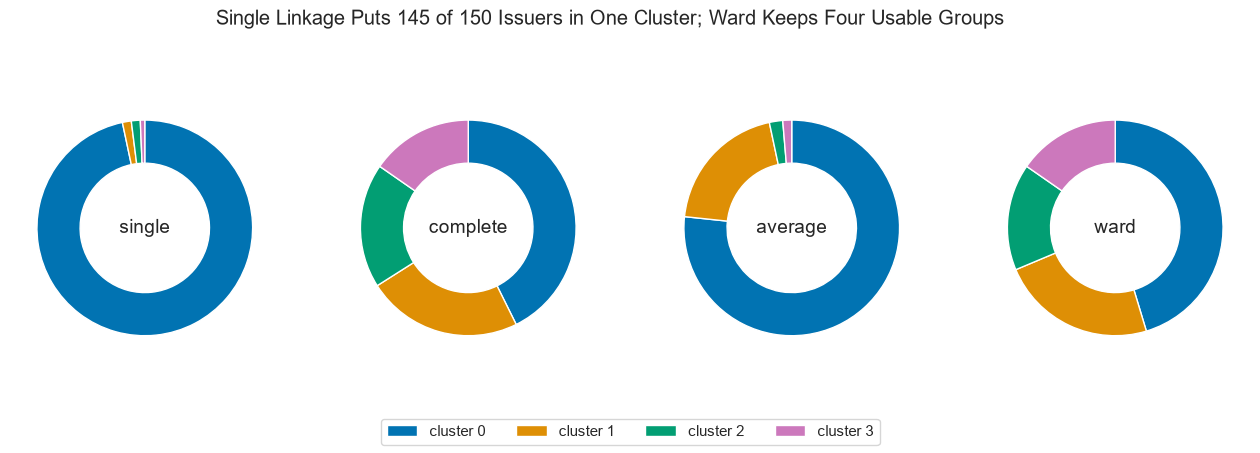

In [28]:
# one donut per linkage: the ring is the 150 issuers, one slice per cluster; width= cuts out the middle
# startangle=90 and counterclock=False start at the top and run clockwise; fig.legend is one legend for all four
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (method, counts) in zip(axes, sizes.items()):
    ax.pie(counts, colors=colours[:4], startangle=90, counterclock=False, wedgeprops={"width": 0.4})
    ax.text(0, 0, method, ha="center", va="center", fontsize=14)
fig.legend([f"cluster {c}" for c in range(4)], loc="lower center", ncol=4)
fig.suptitle("Single Linkage Puts 145 of 150 Issuers in One Cluster; Ward Keeps Four Usable Groups")
plt.show()

Single linkage leaves 145 issuers in one cluster and 5 stragglers in three tiny ones.

Joining by the nearest pair lets a cluster grow like a chain, one close neighbour at a time: **chaining**.

Average leaves 115, 30, 3 and 2; complete 64, 35, 28 and 23; ward 68, 35, 24 and 23.

## The Top of Each Tree

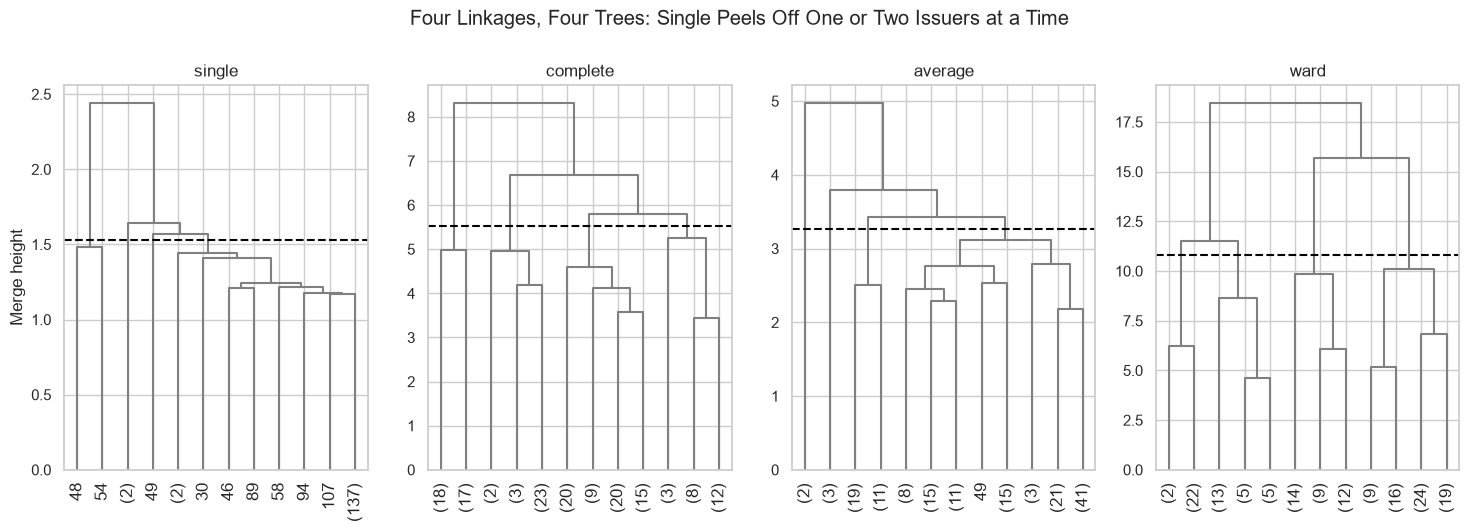

In [29]:
# the top 12 branches of each tree, each with its own cut into four clusters
# along the bottom, (n) is a branch of n issuers and a plain number is one issuer's row; leaf_rotation turns the labels
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (method, tree) in zip(axes, trees.items()):
    dendrogram(tree, truncate_mode="lastp", p=12, color_threshold=0, above_threshold_color="gray", leaf_rotation=90, ax=ax)
    ax.axhline((tree[-4, 2] + tree[-3, 2]) / 2, color="black", linestyle="--")
    ax.set_title(method)
axes[0].set_ylabel("Merge height")
fig.suptitle("Four Linkages, Four Trees: Single Peels Off One or Two Issuers at a Time", y=1.03)
plt.show()

Single's top merges each add one or two issuers to one big branch.

Ward's top merges join large branches.

Heights are not comparable across panels: each linkage measures in its own way.

**Same distances, four meanings of close, four answers. Next: which tree keeps the distances best.**

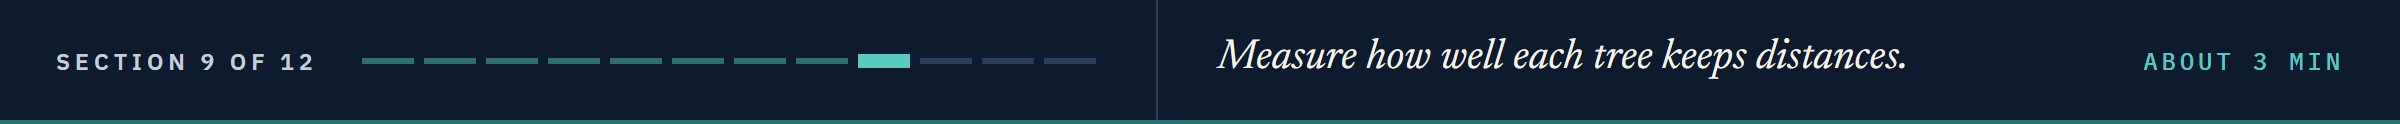

# How Faithful Is the Tree

## Cophenetic Distance

The **cophenetic distance** of two issuers is the height at which the tree first joins them.
`cophenet` gives it for every pair, as one long list in `pdist`'s order.

In [30]:
# the tree height of every pair, laid out as a table like the distances
tree_heights = pd.DataFrame(squareform(cophenet(merges)), index=issuers.index, columns=issuers.index)
for first, second in [("CLAY", "WYXR"), ("BEZE", "BEZH")]:
    print(first, second, " distance", round(distances.loc[first, second], 4), " tree height", round(tree_heights.loc[first, second], 4))

CLAY WYXR  distance 0.2075  tree height 0.2075
BEZE BEZH  distance 2.0227  tree height 15.6804


CLAY and WYXR: 0.2075 both ways, because the tree joins them first.

BEZE and BEZH are 2.0227 apart, but the tree only joins them at 15.68, near the top.

## Every Pair, Distance Against Tree Height

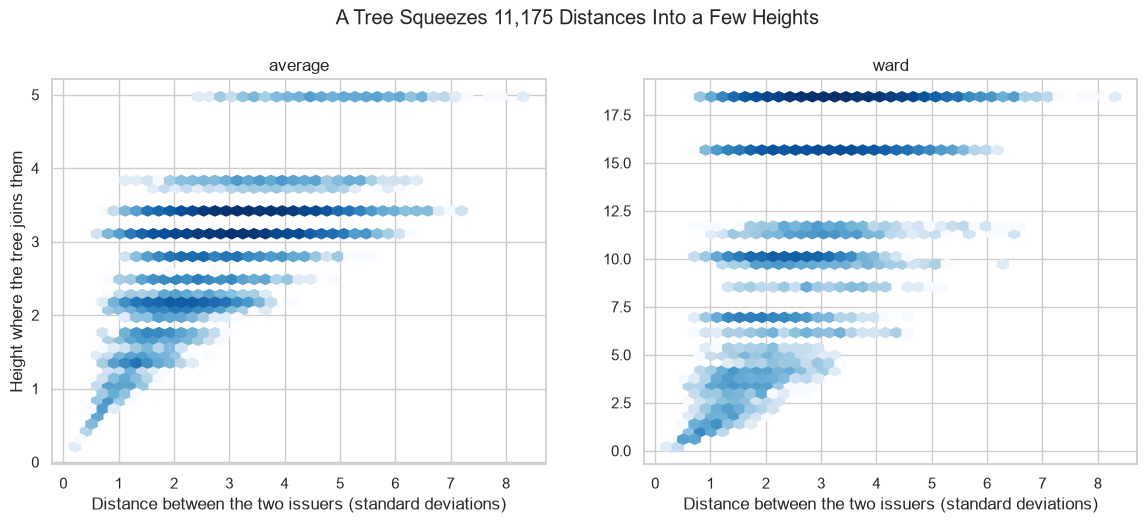

64.6 percent of pairs join at ward's top two merges


In [31]:
# every pair: its distance along the bottom, the height where the tree joins it up the side; darker hexagons, more pairs
# bins="log" shades by the log of each count, so a hexagon of 5 pairs still shows beside one of 5,000
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["average", "ward"]):
    ax.hexbin(pair_distances, cophenet(trees[method]), gridsize=40, mincnt=1, cmap="Blues", bins="log")
    ax.set_title(method)
    ax.set_xlabel("Distance between the two issuers (standard deviations)")
axes[0].set_ylabel("Height where the tree joins them")
fig.suptitle("A Tree Squeezes 11,175 Distances Into a Few Heights", y=1.02)
plt.show()

# the share of pairs ward joins only at its top two merges
print(round((cophenet(trees["ward"]) >= heights.iloc[-2]).mean() * 100, 1), "percent of pairs join at ward's top two merges")

Each flat band is one merge: every pair it joins gets the same height.

Ward joins 64.6 percent of all pairs only at its top two merges, whatever their distance.

Average's heights follow the distances more closely.

## One Number per Linkage

The **cophenetic correlation** is the correlation between every pair's distance and its tree height: near 1, the tree keeps the distances.

In [32]:
# cophenet(tree, distances) also returns the cophenetic correlation, first; beside it each tree's smallest cluster at four
faithful = pd.DataFrame({"cophenetic": {m: cophenet(t, pair_distances)[0] for m, t in trees.items()},
                         "smallest_cluster": {m: min(s) for m, s in sizes.items()}})
faithful.sort_values("cophenetic", ascending=False).round(4)

,cophenetic,smallest_cluster
average,0.6317,2
ward,0.5212,23
complete,0.4903,23
single,0.4637,1


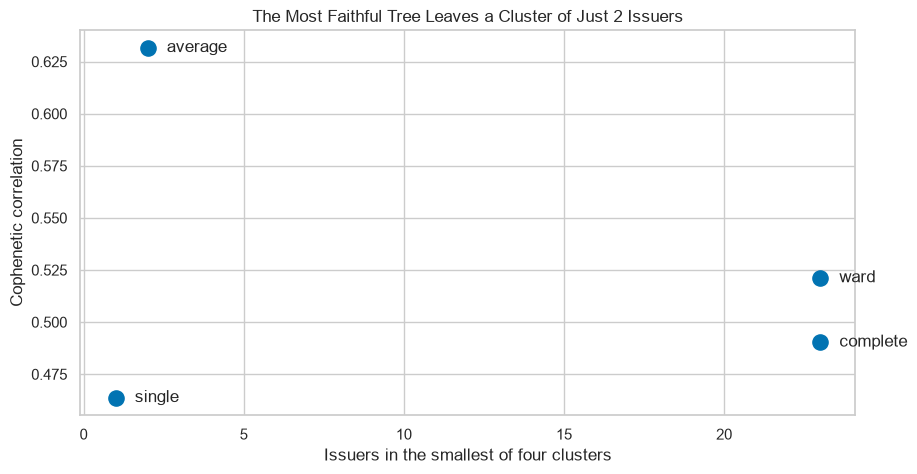

In [33]:
# one labelled point per linkage: how faithful against how usable its four clusters are; iterrows() gives each row's label and values
plt.scatter(faithful["smallest_cluster"], faithful["cophenetic"], s=120)
for method, row in faithful.iterrows():
    plt.text(row["smallest_cluster"] + 0.6, row["cophenetic"], method, va="center", fontsize=12)
plt.xlabel("Issuers in the smallest of four clusters")
plt.ylabel("Cophenetic correlation")
plt.title("The Most Faithful Tree Leaves a Cluster of Just 2 Issuers")
plt.show()

Average keeps the distances best, 0.6317, and leaves clusters of 3 and 2 issuers.

Ward is second, 0.5212, with no cluster smaller than 23.

**Average keeps the distances best; ward keeps groups big enough to describe, so ward stays.**

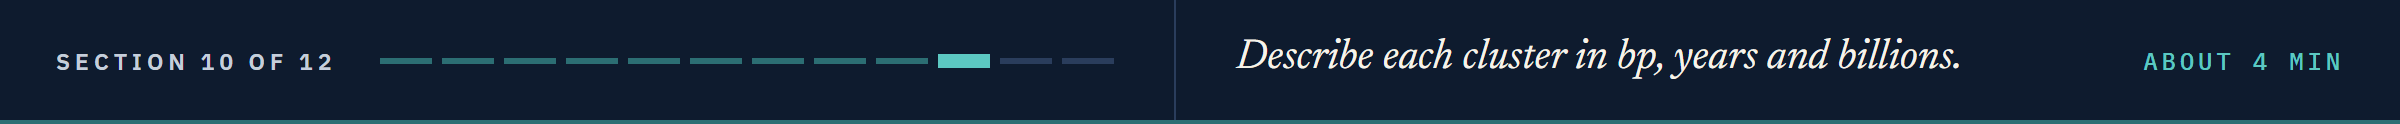

# Profiling the Clusters

## The Profile in bp, Years and Billions

A **cluster profile** is one line per cluster: how many issuers, and the median of each column in the file's own units.

In [34]:
# a cluster profile: the median of each column per cluster, and how many rows each cluster holds
def cluster_profile(rows, labels, columns):
    profile = rows.groupby(labels)[columns].median()
    profile["issuers"] = rows.groupby(labels).size()
    return profile

# the four ward clusters from the unscaled table, and the percent of each rated investment grade
units = ["median_oas", "median_duration", "bonds", "amount_bn", "score"]
profile = cluster_profile(issuers, issuers["cluster"], units)
profile["ig_percent"] = (issuers["grade"] == "Investment Grade").groupby(issuers["cluster"]).mean() * 100
profile.round(2)

,median_oas,median_duration,bonds,amount_bn,score,issuers,ig_percent
cluster,,,,,,,
0,124.5,6.48,7.0,8.70,9.0,68,72.06
1,342.0,5.23,4.0,6.05,14.0,35,11.43
2,68.0,7.32,3.5,4.03,5.0,24,100.00
3,73.0,3.57,5.0,7.50,6.0,23,95.65


Cluster 0: 68 issuers, 124.5 bp, 6.48 years, 7 bonds, 8.70 billion; 72.06 percent investment grade.

Cluster 1: 35 issuers, 342 bp, a median score of 14 (B+); 11.43 percent investment grade.

Cluster 2: 24 issuers, 68 bp, the longest at 7.32 years, the fewest bonds and the smallest size; all investment grade.

Cluster 3: 23 issuers, 73 bp, the shortest at 3.57 years; 95.65 percent investment grade.

## Colour in Deviations, Numbers in Units

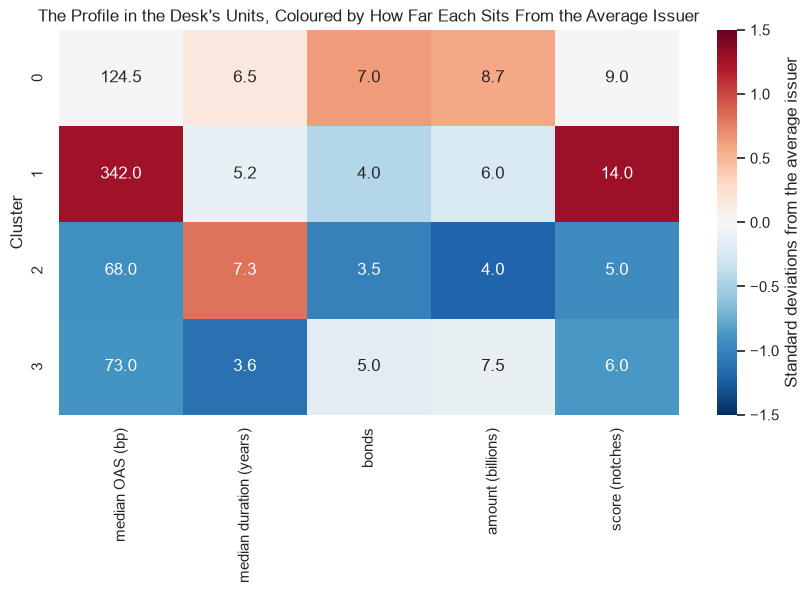

In [35]:
# colour from the scaled averages, numbers from the profile in bp, years, bonds, billions and notches
labels = ["median OAS (bp)", "median duration (years)", "bonds", "amount (billions)", "score (notches)"]
sns.heatmap(means, annot=profile[units].to_numpy(), fmt=".1f", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5,
            xticklabels=labels, annot_kws={"fontsize": 12}, cbar_kws={"label": "Standard deviations from the average issuer"})
plt.ylabel("Cluster")
plt.title("The Profile in the Desk's Units, Coloured by How Far Each Sits From the Average Issuer")
plt.show()

The colour says how unusual a cluster is on a column; the number says it in the desk's unit.

## Inside Each Cluster

Q. Do the clusters have hard edges on spread?

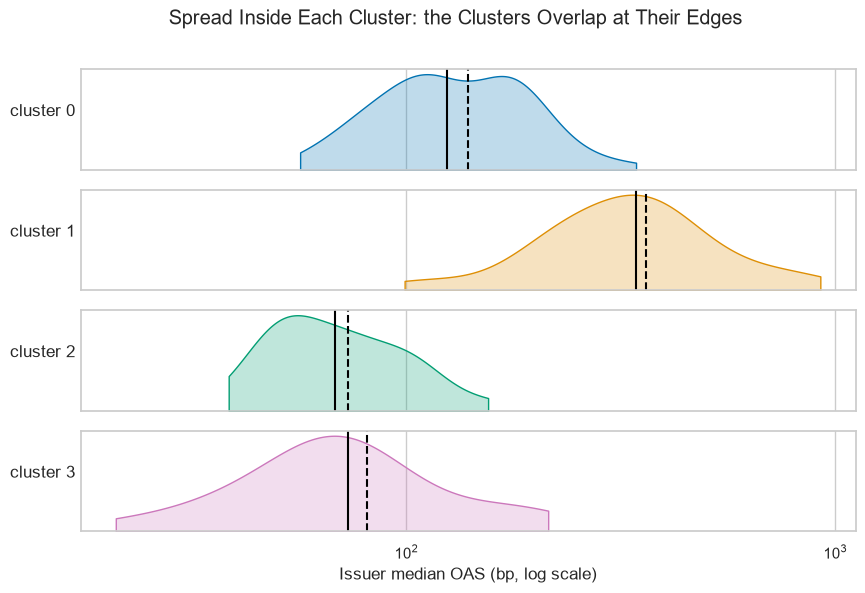

In [36]:
# one smooth curve of issuer median OAS per cluster, stacked like a ridge; the median solid, the mean dashed
# cut=0, as on Course 1's violins, stops each curve at its cluster's tightest and widest issuer
fig, axes = plt.subplots(4, 1, figsize=(10, 6), sharex=True)
for cluster, ax in enumerate(axes):
    oas = issuers.loc[issuers["cluster"] == cluster, "median_oas"]
    sns.kdeplot(x=oas, log_scale=True, fill=True, cut=0, color=colours[cluster], ax=ax)
    ax.axvline(oas.median(), color="black")
    ax.axvline(oas.mean(), color="black", linestyle="--")
    ax.set_ylabel(f"cluster {cluster}", rotation=0, ha="right")
    ax.set_yticks([])
axes[-1].set_xlabel("Issuer median OAS (bp, log scale)")
fig.suptitle("Spread Inside Each Cluster: the Clusters Overlap at Their Edges")
plt.show()

In [37]:
# each cluster's tightest and widest issuer, its median and its mean, in bp
issuers.groupby("cluster")["median_oas"].agg(["min", "max", "median", "mean"]).round(1)

,min,max,median,mean
cluster,,,,
0,56.5,343.0,124.5,138.9
1,99.0,922.5,342.0,362.1
2,38.5,155.0,68.0,73.0
3,21.0,214.0,73.0,80.9


Cluster 1 runs from 99 to 922.5 bp, and its mean sits 20.1 bp above its median: a few wide issuers pull the mean.

That is why a profile reports medians.

Cluster 0 reaches 343 bp, wider than cluster 1's median: neighbours share their edges.

A profile describes the issuers in this file: it ranks no cluster and says nothing about any spread to come.

**Each cluster now has a line a desk can read. Next: whether Day 12's K-means finds the same groups.**

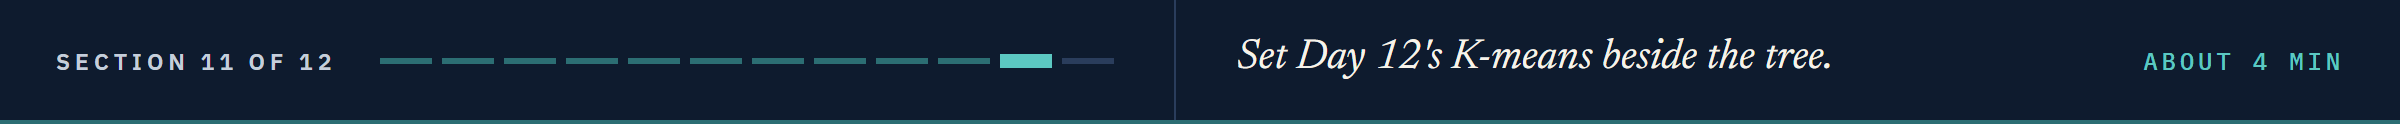

# K-Means Against the Tree

## K-Means on the Same Issuers

In [38]:
# Day 12's K-means on the same scaled issuers, four clusters, numbered by size
kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled)
issuers["kmeans"] = by_size(kmeans.labels_).to_numpy()
cluster_profile(issuers, issuers["kmeans"], units).round(2)

,median_oas,median_duration,bonds,amount_bn,score,issuers
kmeans,,,,,,
0,100.0,6.40,7.0,9.75,8.0,45
1,191.0,5.71,4.0,5.57,11.0,38
2,62.5,6.62,4.0,5.12,5.0,38
3,252.0,5.11,7.0,9.50,13.0,29


K-means makes four clusters of 45, 38, 38 and 29.
Two of them hold the wider-spread issuers, 191 and 252 bp, one with 4 bonds and 5.57 billion, the other with 7 bonds and 9.50 billion.

## Where Each Issuer Went

**Predict 4**

Q. Ward's cluster 1 holds 35 issuers, the widest spreads of the four clusters. How many of them share the K-means cluster that takes the most of them?

In [39]:
# how many of each ward cluster's issuers land in each K-means cluster
moves = pd.crosstab(issuers["cluster"], issuers["kmeans"], rownames=["ward"], colnames=["K-means"])

# issuers in the K-means cluster that holds most of their ward cluster, and each method's silhouette
print(moves.max(axis=1).sum(), "of 150 sit with the majority of their ward cluster")
print("Silhouette: K-means", round(silhouette_score(X_scaled, issuers["kmeans"]), 4),
      " ward", round(silhouette_score(X_scaled, issuers["cluster"]), 4))
moves

88 of 150 sit with the majority of their ward cluster
Silhouette: K-means 0.2577  ward 0.2153


K-means,0,1,2,3
ward,,,,
0,36,12,5,15
1,0,20,1,14
2,0,1,23,0
3,9,5,9,0


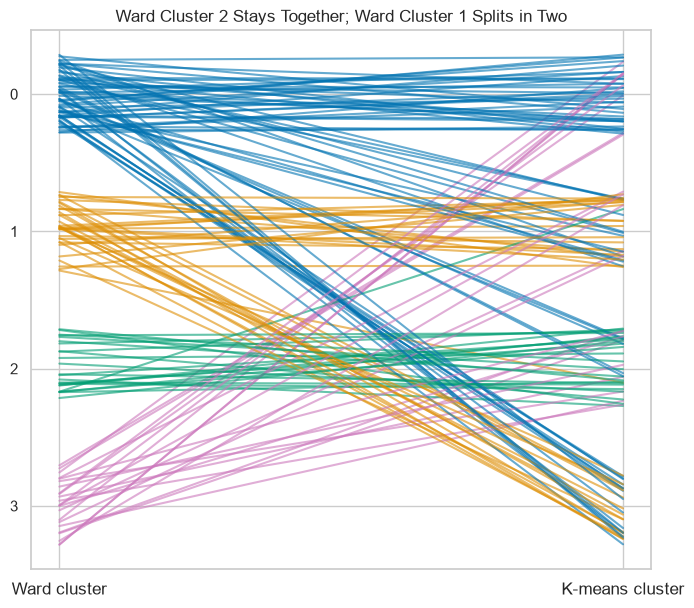

In [40]:
# one line per issuer from its ward cluster (left) to its K-means cluster (right), in its ward cluster's colour
# a little seeded scatter up and down keeps the 150 lines apart
rng = np.random.default_rng(SEED)
left = issuers["cluster"] + rng.uniform(-0.3, 0.3, len(issuers))
right = issuers["kmeans"] + rng.uniform(-0.3, 0.3, len(issuers))
fig, ax = plt.subplots(figsize=(8, 7))
for y0, y1, cluster in zip(left, right, issuers["cluster"]):
    ax.plot([0, 1], [y0, y1], color=colours[cluster], alpha=0.6)
ax.set_xticks([0, 1], ["Ward cluster", "K-means cluster"], fontsize=12)
ax.set_yticks(range(4))
ax.invert_yaxis()
ax.set_title("Ward Cluster 2 Stays Together; Ward Cluster 1 Splits in Two")
plt.show()

20 of ward cluster 1's 35 land in one K-means cluster and 14 in another: K-means splits the wide issuers by size.

Ward cluster 2 sends 23 of 24 to one K-means cluster.

Ward cluster 0 spreads over all four.

88 of 150 issuers sit with the majority of their ward cluster.

K-means scores higher on the silhouette, 0.2577 against 0.2153: the silhouette rewards tight clusters around a centre, which is what K-means builds.

## Taking Out the Rating Score

Q. The pair plot showed log OAS and the score saying the same thing. What if the score goes?

In [41]:
# the same ward tree on four columns, scaled again and cut into four
four = ["median_log_oas", "median_duration", "bonds", "amount_bn"]
without = by_size(fcluster(linkage(StandardScaler().fit_transform(issuers[four]), method="ward"), t=4, criterion="maxclust"))
moved = pd.crosstab(issuers["cluster"], without.to_numpy())
print("Sizes:", without.value_counts().tolist())
print(moved.max(axis=1).sum(), "of 150 stay with the majority of their old cluster")

Sizes: [44, 42, 39, 25]
84 of 150 stay with the majority of their old cluster


Dropping one column leaves 66 issuers outside their old cluster's majority, more than the 62 that K-means moved: the columns chosen matter as much as the method.

**Two sound methods, two sets of groups: a clustering is one description of the issuers, not the answer.**

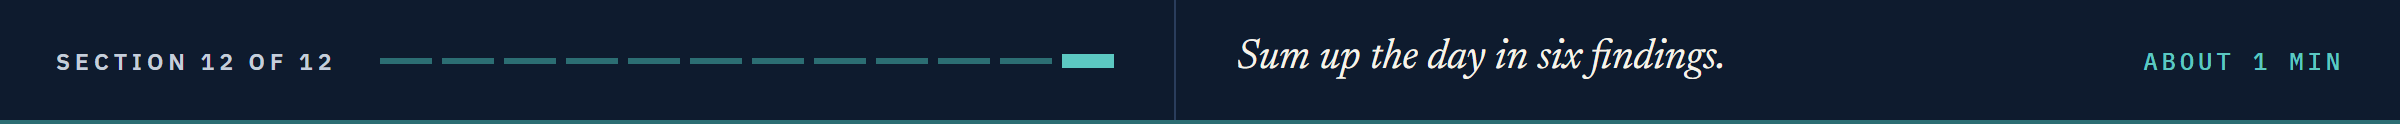

# Insights and Conclusion

The tree comes first and the number of clusters after: one tree holds every cut.

The merge heights show where groups part: flat for over a hundred merges, then a steep climb.

The linkage changes everything: single leaves 145 issuers in one cluster, ward 68 in its largest.

The most faithful tree, average, leaves clusters too small to describe; ward keeps four usable groups.

A profile in bp, years and billions describes each cluster and ranks none.

K-means and the tree agree on 88 of 150 issuers: a clustering is one description, not the answer.

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Build one row per issuer from its bonds with `groupby` and medians.
* Join rows from the bottom up with `linkage` and read the result as a dendrogram.
* Cut a tree with `fcluster`, by a number of clusters or a height, and say why you cut where you did.
* Compare linkages by their cluster sizes and their cophenetic correlation.
* Profile clusters in the file's own units, and set them beside K-means without ranking them.

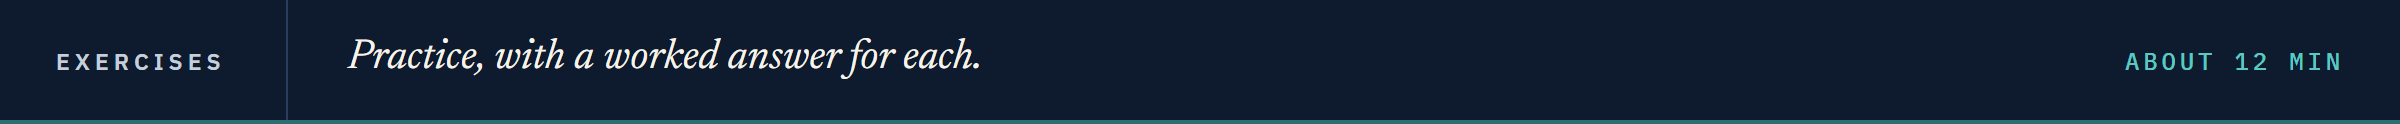

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [42]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Five Clusters**

Q. Cut the ward tree into five clusters and number them by size. Store the sizes, largest first, as a list in `ex1_sizes`, and in `ex1_split` the number of the four-cluster cut's cluster that splits in two.

In [43]:
# your code here
ex1_sizes = ...
ex1_split = ...

In [44]:
check("Exercise 1 the sizes", ex1_sizes, [43, 35, 25, 24, 23])
check("Exercise 1 the cluster that splits", ex1_split, 0)

Exercise 1 the sizes: not attempted yet
Exercise 1 the cluster that splits: not attempted yet


### Exercise 2

**The Faithful Tree**

Q. Store the average linkage tree's cophenetic correlation in `ex2_cophenetic` and its four cluster sizes, largest first, as a list in `ex2_sizes`. Would you profile those four clusters for a desk?

In [45]:
# your code here
ex2_cophenetic = ...
ex2_sizes = ...

In [46]:
check("Exercise 2 the cophenetic correlation", ex2_cophenetic, 0.6316509859267213)
check("Exercise 2 the sizes", ex2_sizes, [115, 30, 3, 2])

Exercise 2 the cophenetic correlation: not attempted yet
Exercise 2 the sizes: not attempted yet


### Exercise 3

**The Largest Cluster**

Q. Write `largest_cluster(labels)`, which returns the cluster number that occurs most often. Store its result on `[2, 2, 1, 3, 2, 1]` in `ex3_small` and on `by_count`, `fcluster`'s own labels, in `ex3_tree`.

In [47]:
# your code here
ex3_small = ...
ex3_tree = ...

In [48]:
check("Exercise 3 the small list", ex3_small, 2)
check("Exercise 3 fcluster's labels", ex3_tree, 4)

Exercise 3 the small list: not attempted yet
Exercise 3 fcluster's labels: not attempted yet


### Exercise 4: AI check

**The Desk's Spread Line**

You asked an AI assistant for each cluster's median OAS in bp, for the desk's one-line profile.
This came back.
It runs and gives one number per cluster.
Test it against what you already know, then find the one bug.

In [49]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def median_oas_bp(labels):
    # each cluster's median OAS in bp, for the desk's one-line profile
    return X_scaled.groupby(labels)["median_log_oas"].median().round(4).tolist()

# the check against what we know: the function's numbers, then the profile's median OAS
print(median_oas_bp(issuers["cluster"]))
print(profile["median_oas"].tolist())

[-0.078, 1.3502, -0.9345, -0.833]
[124.5, 342.0, 68.0, 73.0]


Q. A median OAS below 0 bp cannot be right, and the profile says 124.5 bp for cluster 0. Fix the one wrong line so the function reads the unscaled table, and store the fixed function's result on `issuers["cluster"]` in `ex4_oas`.

In [50]:
# your code here
ex4_oas = ...

In [51]:
check("Exercise 4 the fixed function's medians", ex4_oas, [124.5, 342.0, 68.0, 73.0])

Exercise 4 the fixed function's medians: not attempted yet


## Congratulations!

You grouped 150 issuers without choosing the number of groups first, which K-means could not do.
You read a merge table, watched the heights climb, and drew the whole family tree of the issuers.
You moved the cut, weighed four linkages, and chose ward with your reasons stated.
You wrote a profile a desk can read in bp, years and billions, and you found that K-means agrees on 88 of 150.
In Day 14 you squeeze many columns into a few with principal components, and draw the issuers on a page.

[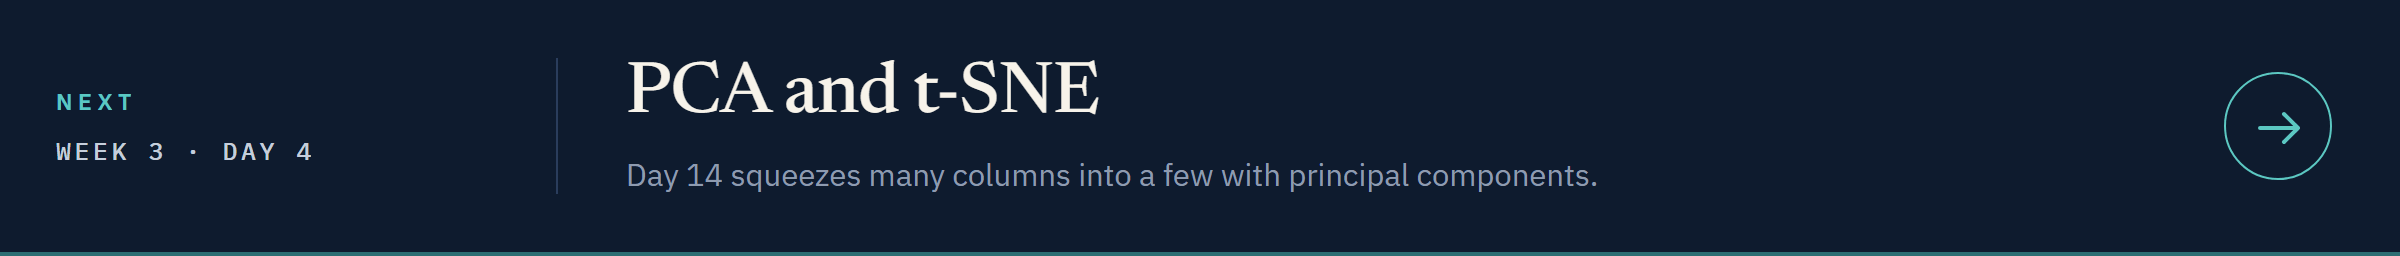](../day4/14_pca_and_t_sne.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day4/14_pca_and_t_sne.ipynb)